<center>
<h1> Laboratorio PyCaret </h1>

<b> John González </b>

30 de septiembre de 2023

Tarea de Gustavo Cardona y Moises Arcia.

<p>
<img src='https://raw.githubusercontent.com/pycaret/pycaret/master/docs/images/logo.png' height=50/>
</center>

Pycaret es una librería de Python que permite trabajar con Machine Learning de bajo código. A diferencia de otras librerías como sklearn, keras, pytorch, fast.ai, ... Esta permite tener varios modelos de una manera muy rápida, concentrarse en la preparación de los datos y análisis de resultados. Por debajo utiliza principalmente la libraría sklearn, básicamente Pycaret lo que hace es simplificar su uso.

Nosotros en este notebook vamos a seguir [este tutorial](https://pycaret.gitbook.io/docs/get-started/quickstart)

```bash
uv add pycaret
```

Adicionalmente vamos a instalar sweetviz, una librería especializada para hacer análisis descriptivo exploratorio para machine learning.

```bash
uv add sweetviz
```

## 1. Importar datos

In [1]:
from pycaret.datasets import get_data
get_data()

,Dataset,Data Types,Default Task,Target Variable 1,Target Variable 2,# Instances,# Attributes,Missing Values
0,anomaly,Multivariate,Anomaly Detection,NaN,NaN,1000,10,N
1,france,Multivariate,Association Rule Mining,InvoiceNo,Description,8557,8,N
2,germany,Multivariate,Association Rule Mining,InvoiceNo,Description,9495,8,N
3,bank,Multivariate,Classification (Binary),deposit,NaN,45211,17,N
4,blood,Multivariate,Classification (Binary),Class,NaN,748,5,N
5,cancer,Multivariate,Classification (Binary),Class,NaN,683,10,N
6,credit,Multivariate,Classification (Binary),default,NaN,24000,24,N
7,diabetes,Multivariate,Classification (Binary),Class variable,NaN,768,9,N
8,electrical_grid,Multivariate,Classification (Binary),stabf,NaN,10000,14,N
9,employee,Multivariate,Classification (Binary),left,NaN,14999,10,N


,Dataset,Data Types,Default Task,Target Variable 1,Target Variable 2,# Instances,# Attributes,Missing Values
0,anomaly,Multivariate,Anomaly Detection,NaN,NaN,1000,10,N
1,france,Multivariate,Association Rule Mining,InvoiceNo,Description,8557,8,N
2,germany,Multivariate,Association Rule Mining,InvoiceNo,Description,9495,8,N
3,bank,Multivariate,Classification (Binary),deposit,NaN,45211,17,N
4,blood,Multivariate,Classification (Binary),Class,NaN,748,5,N
5,cancer,Multivariate,Classification (Binary),Class,NaN,683,10,N
6,credit,Multivariate,Classification (Binary),default,NaN,24000,24,N
7,diabetes,Multivariate,Classification (Binary),Class variable,NaN,768,9,N
8,electrical_grid,Multivariate,Classification (Binary),stabf,NaN,10000,14,N
9,employee,Multivariate,Classification (Binary),left,NaN,14999,10,N


Se selecciona trabajar con la tabla `diabetes`

In [2]:
from pycaret.datasets import get_data
datainicial = get_data('diabetes')
print('Dimensiones de la tabla:', datainicial.shape)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable
0,6,148,72,0,33.6,0.627,50,1
1,1,85,66,0,26.6,0.351,31,0
2,8,183,64,0,23.3,0.672,32,1
3,1,89,66,94,28.1,0.167,21,0
4,0,137,40,168,43.1,2.288,33,1


Dimensiones de la tabla: (753, 8)


                                             |          | [  0%]   00:00 -> (? left)


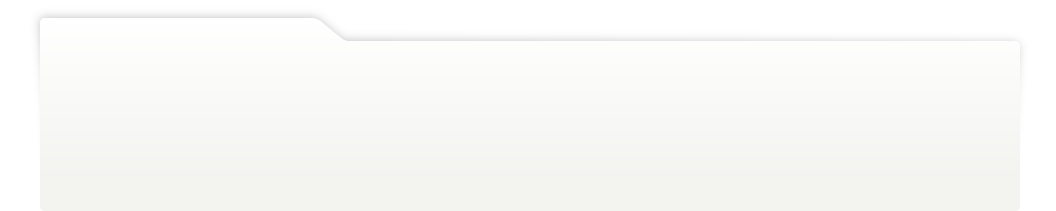
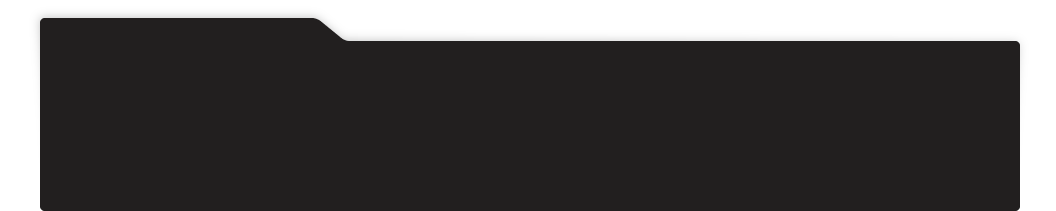
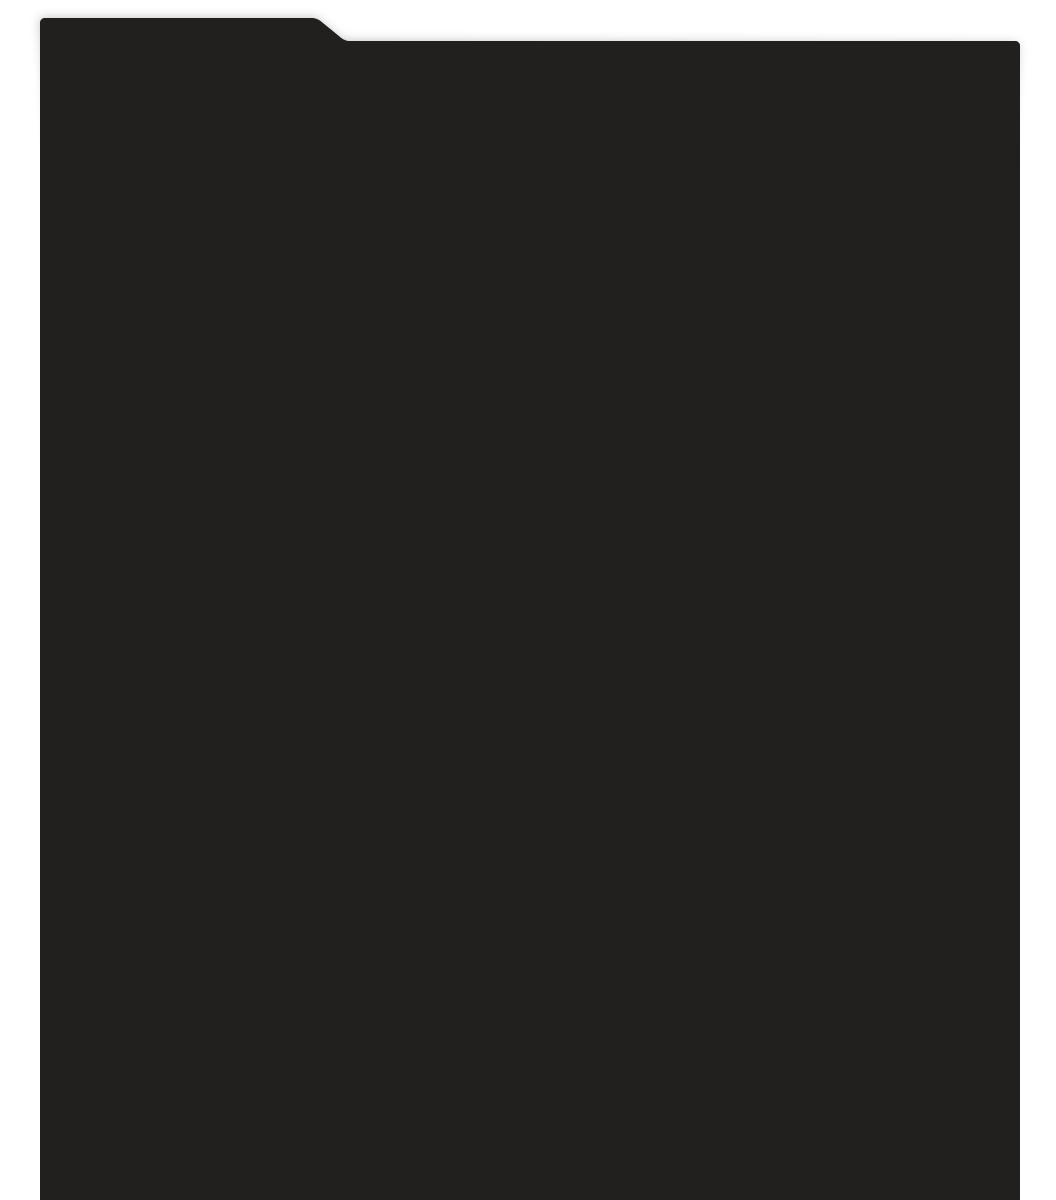
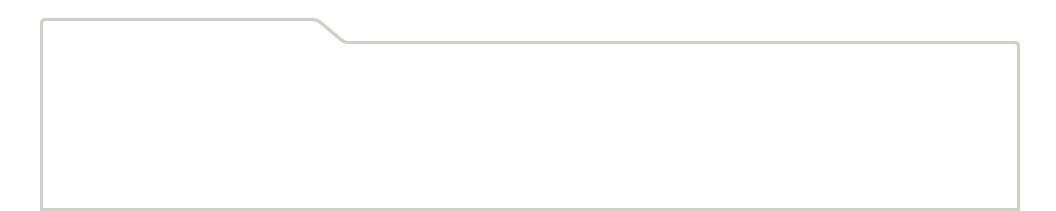
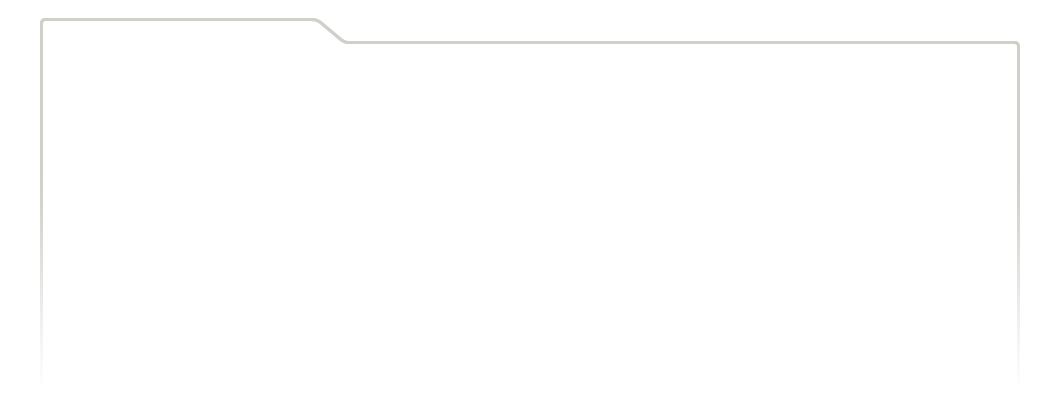
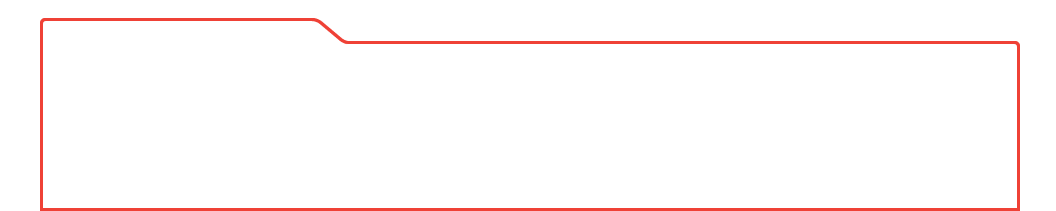
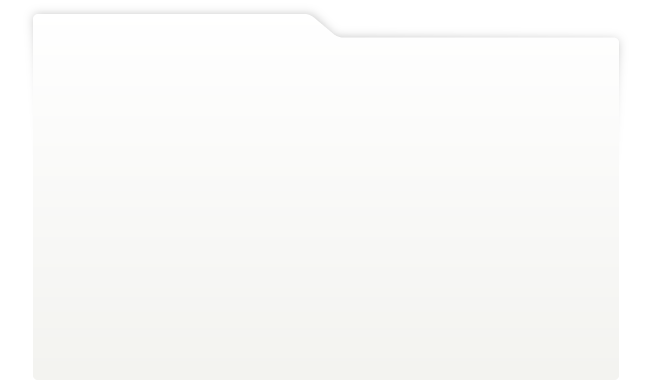
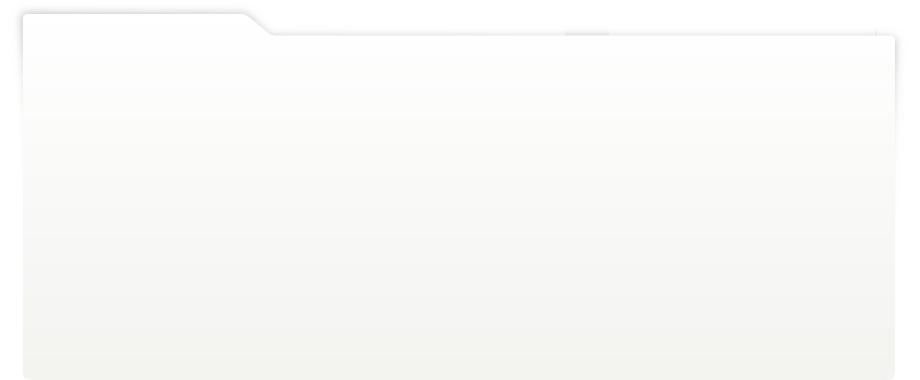
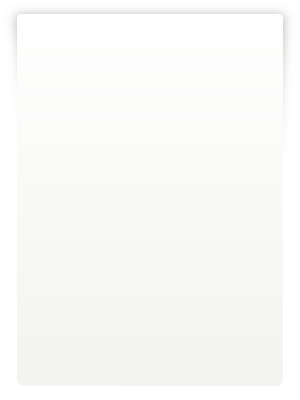
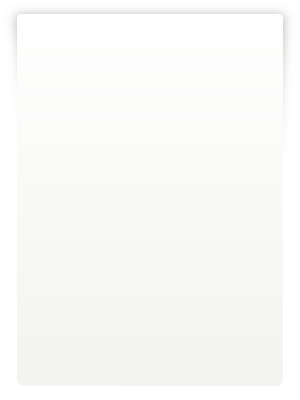
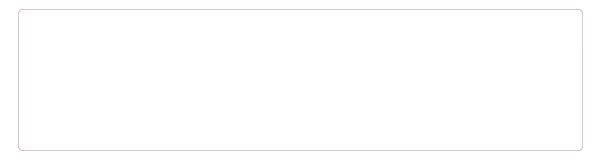
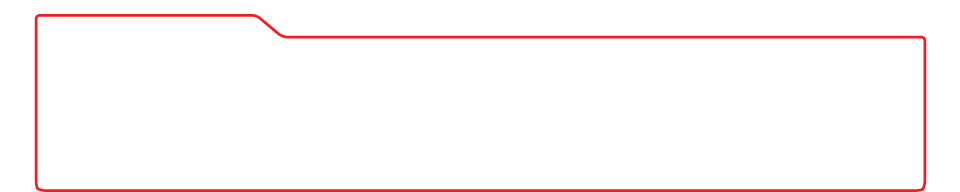
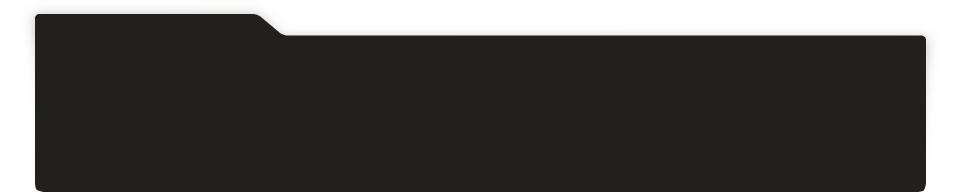
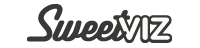
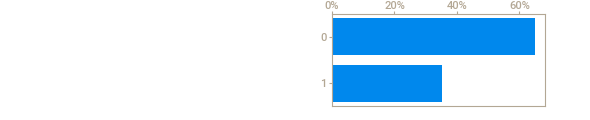
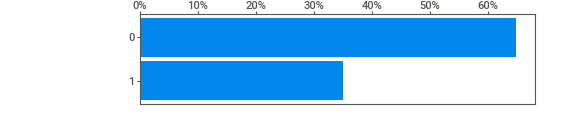
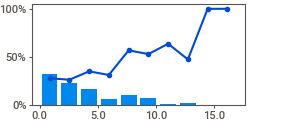
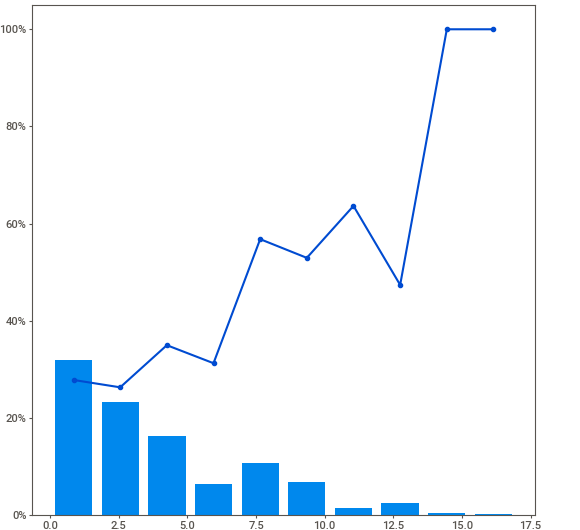
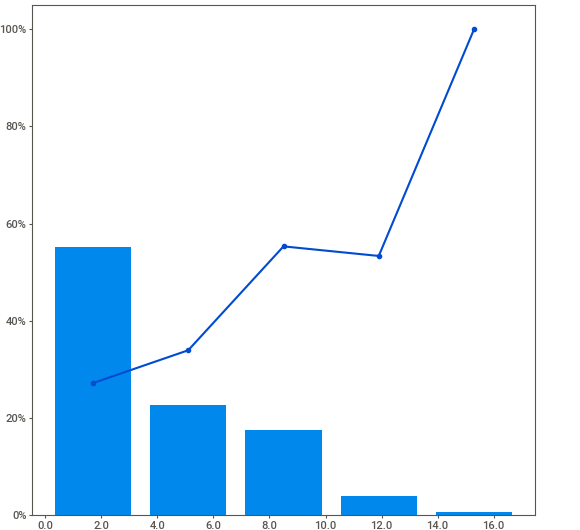
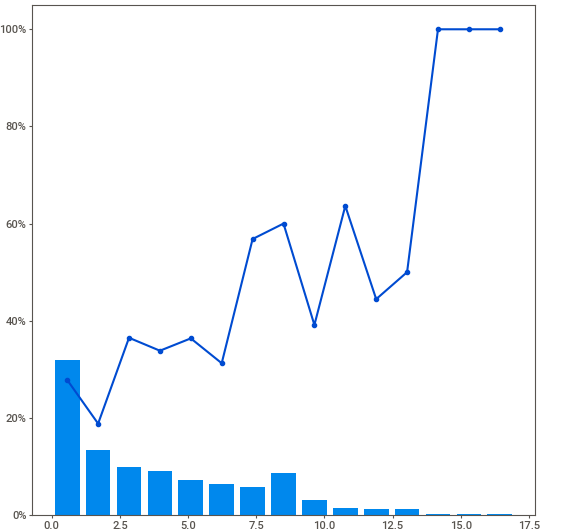
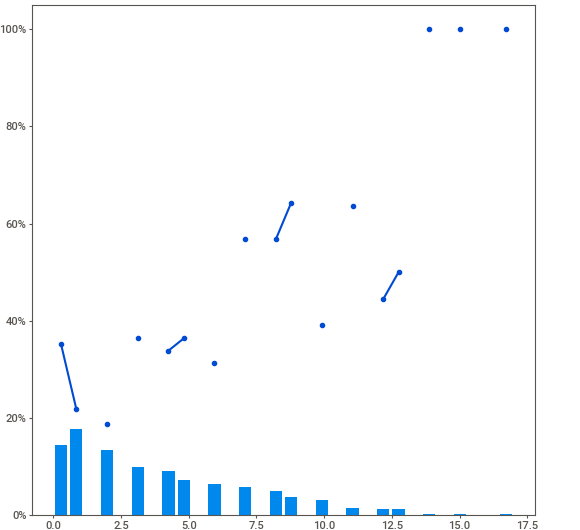
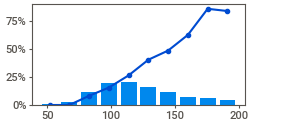
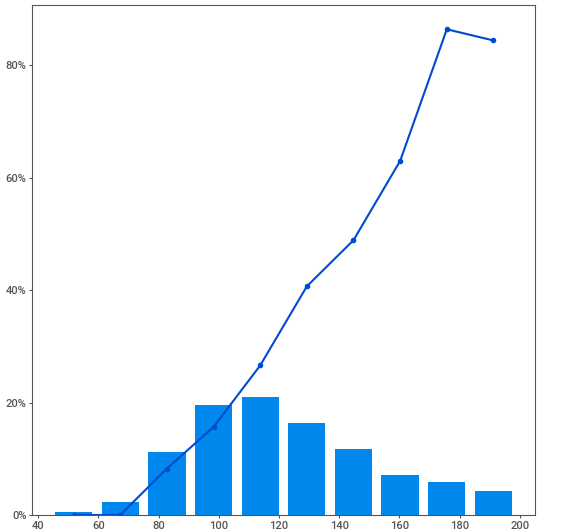
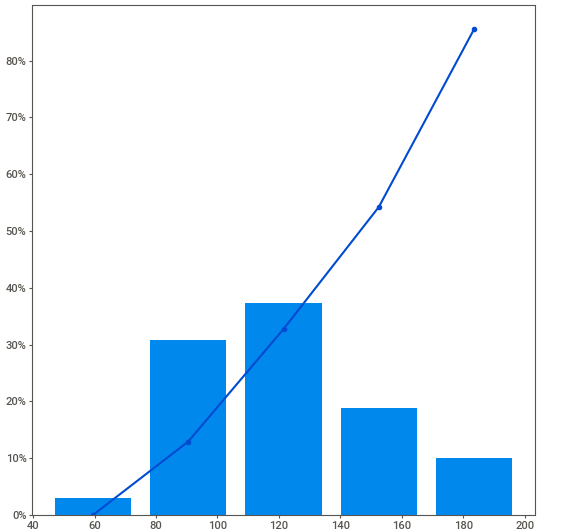
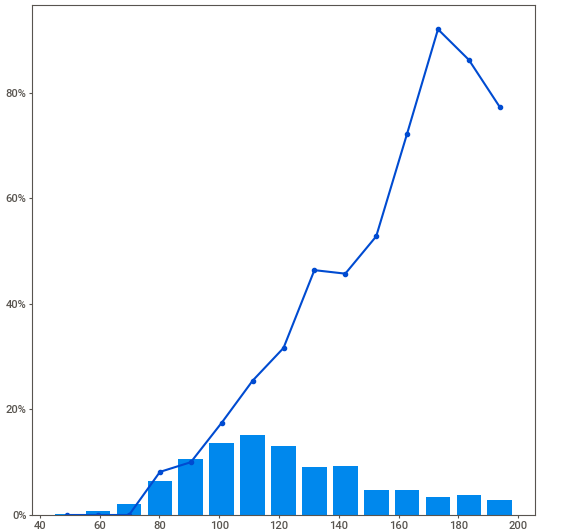
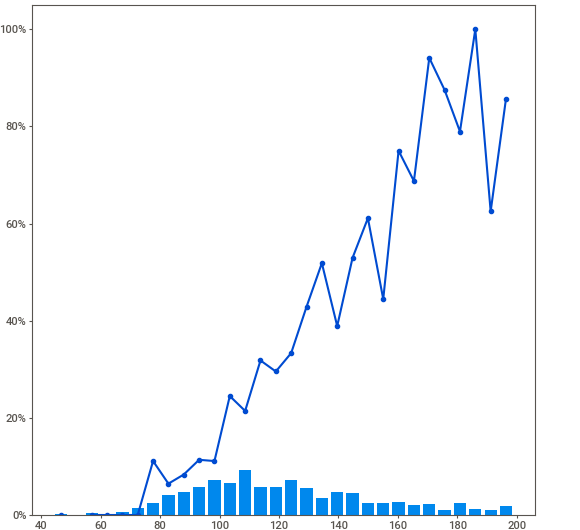
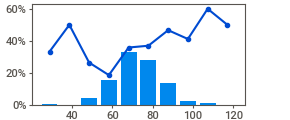
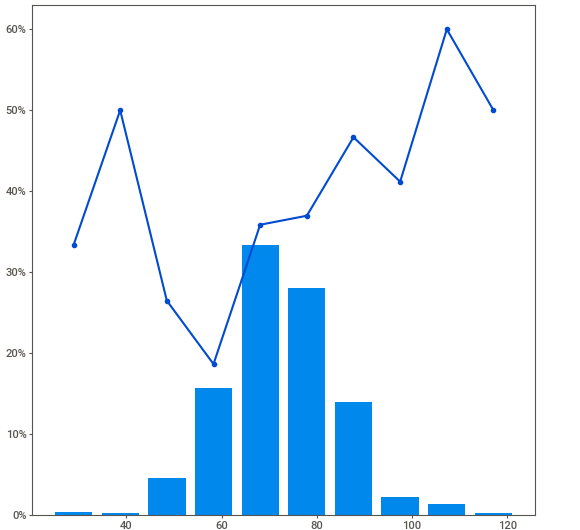
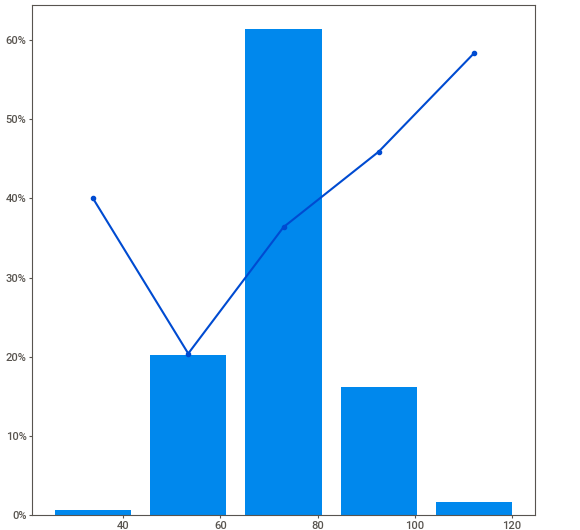
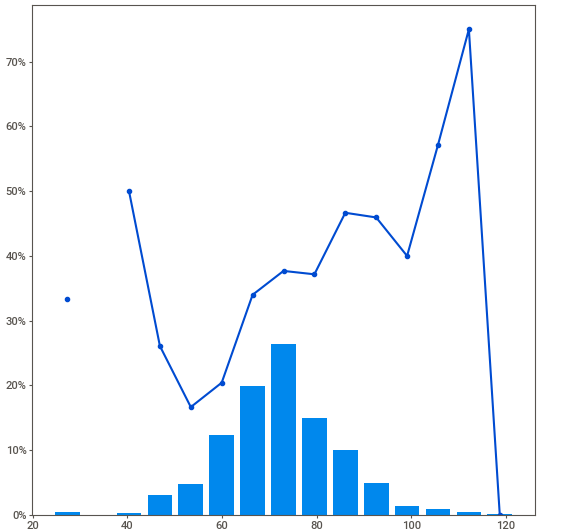
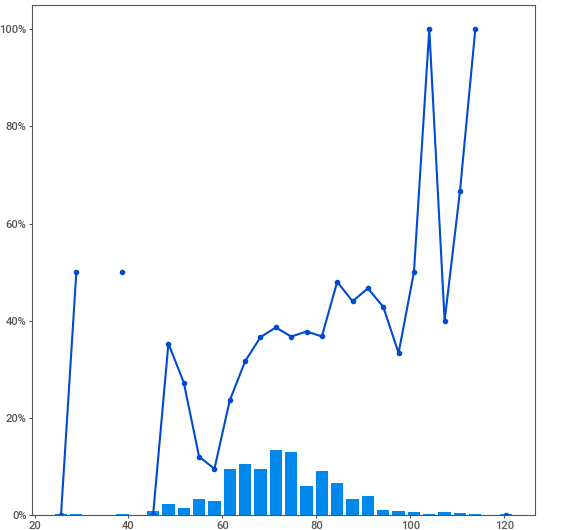
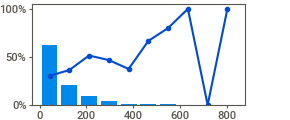
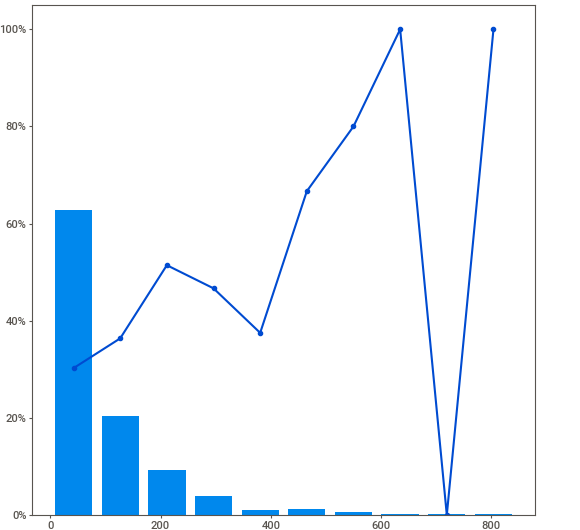
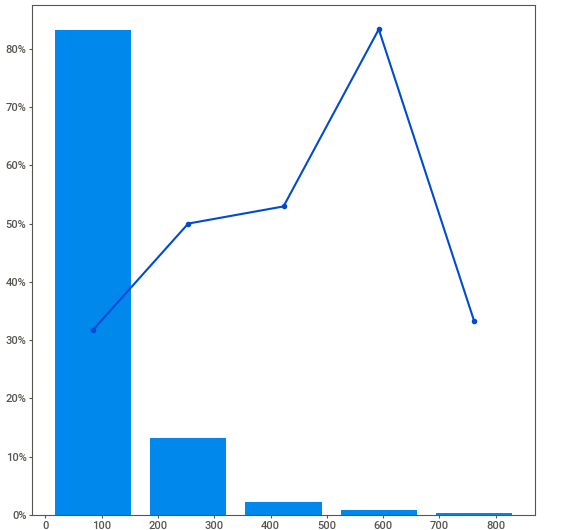
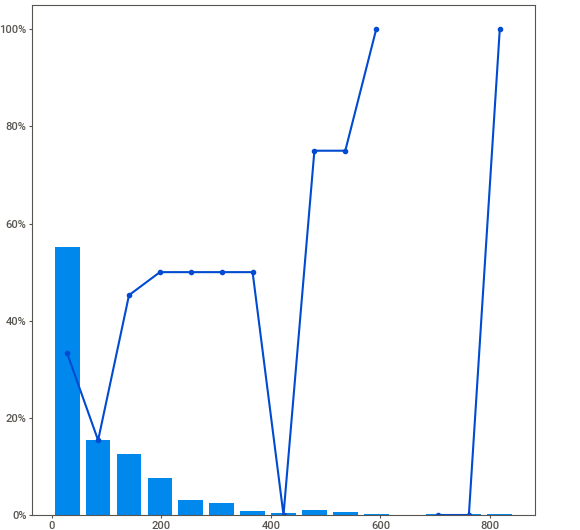
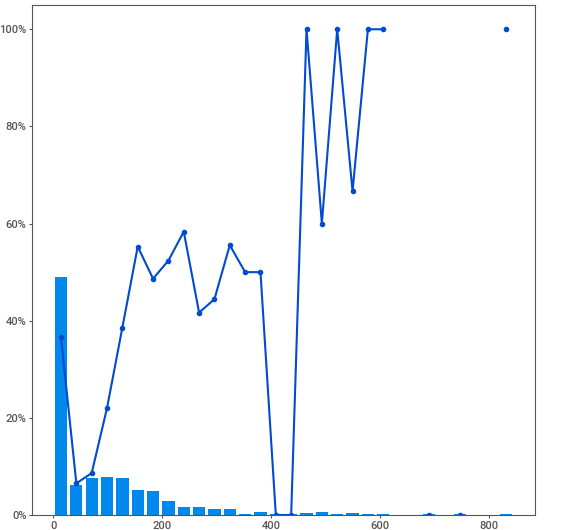
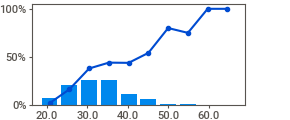
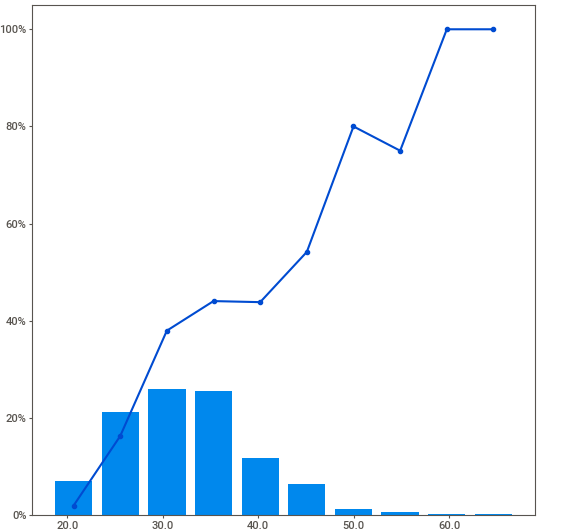
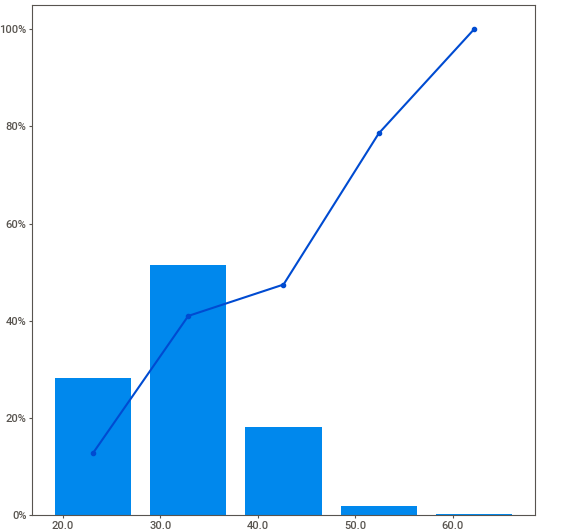
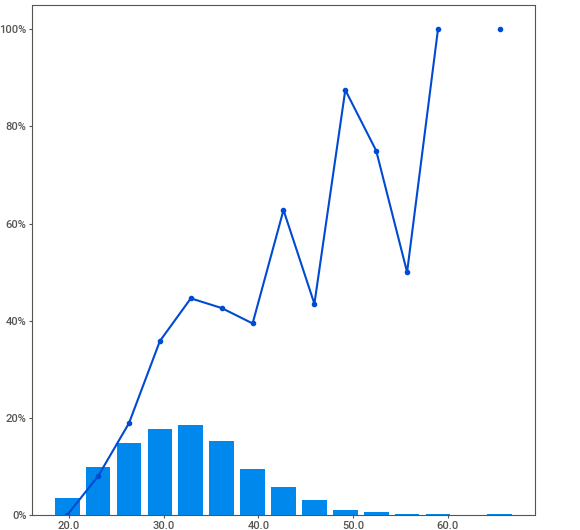
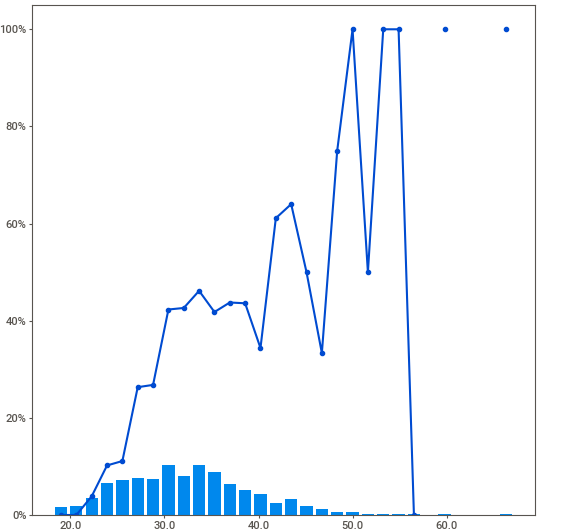
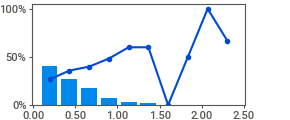
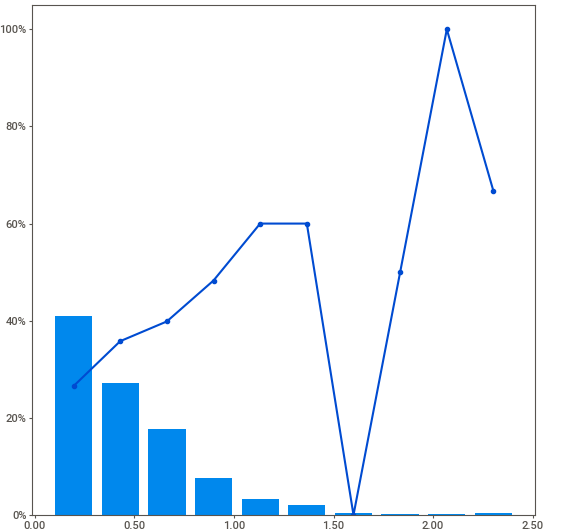
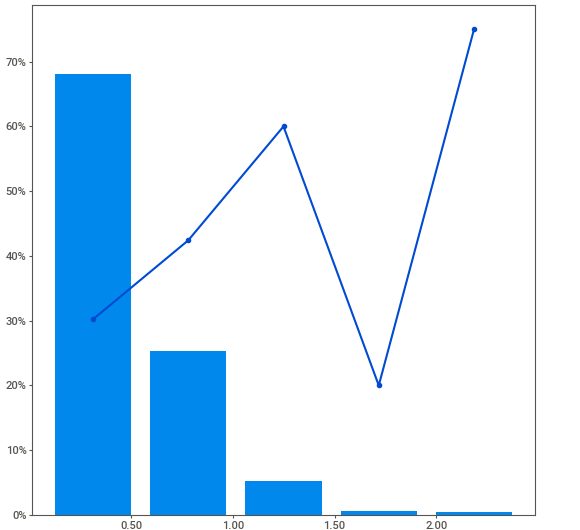
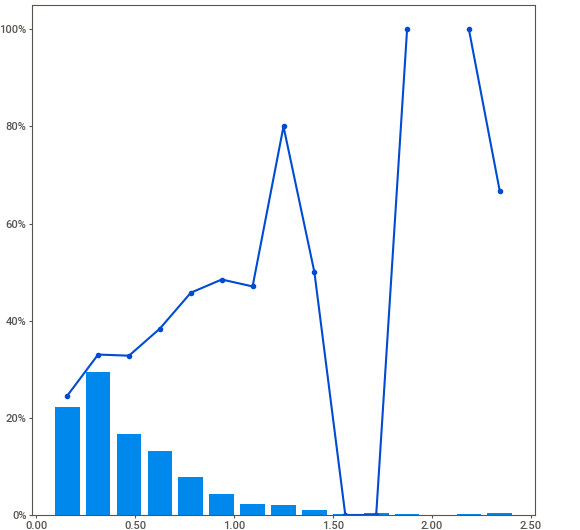
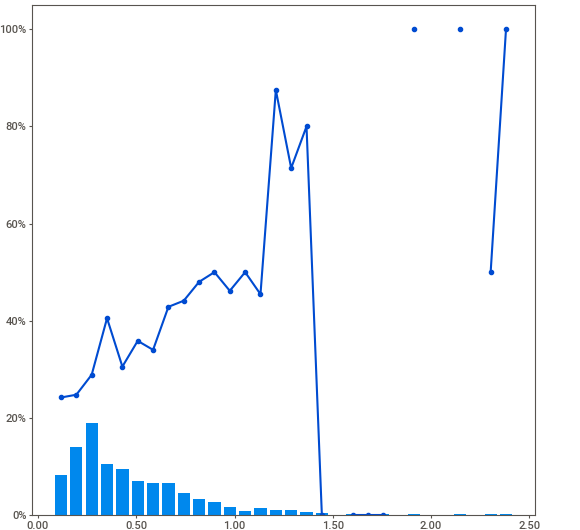
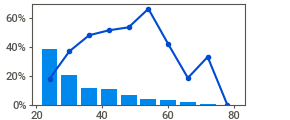
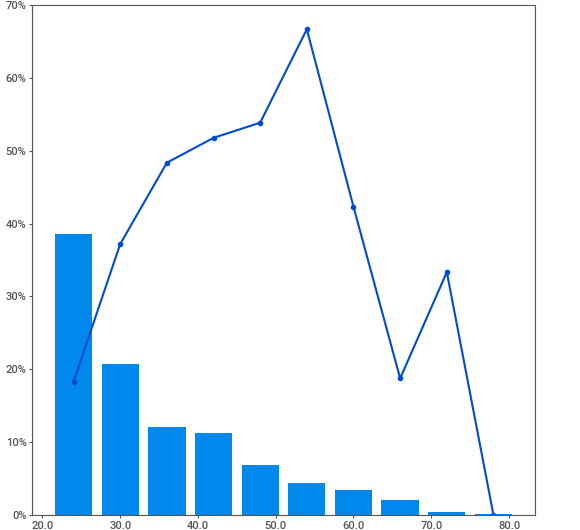
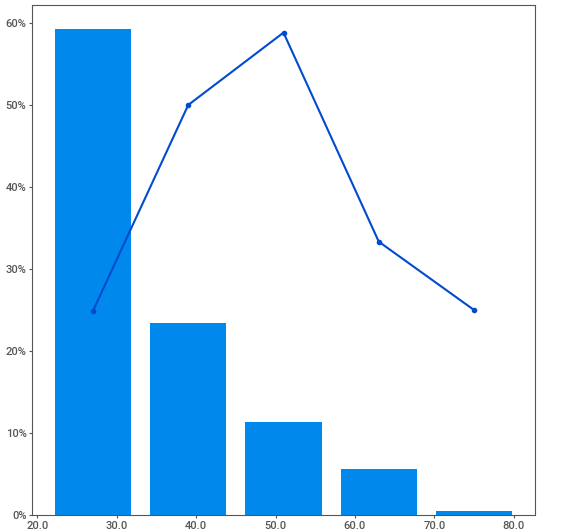
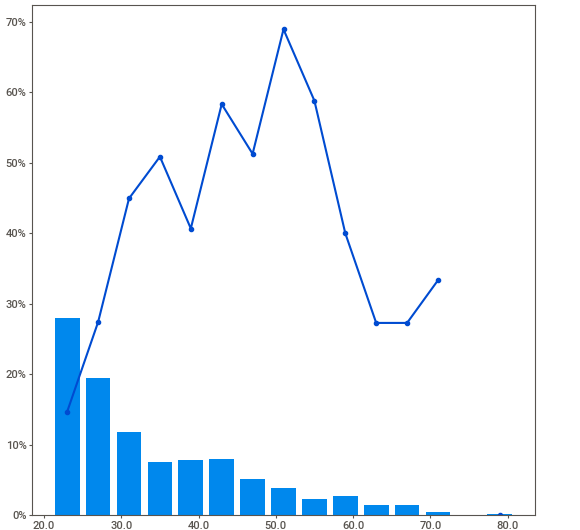
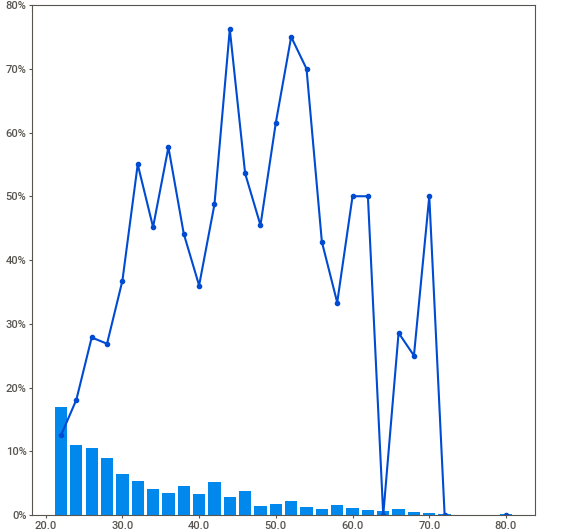
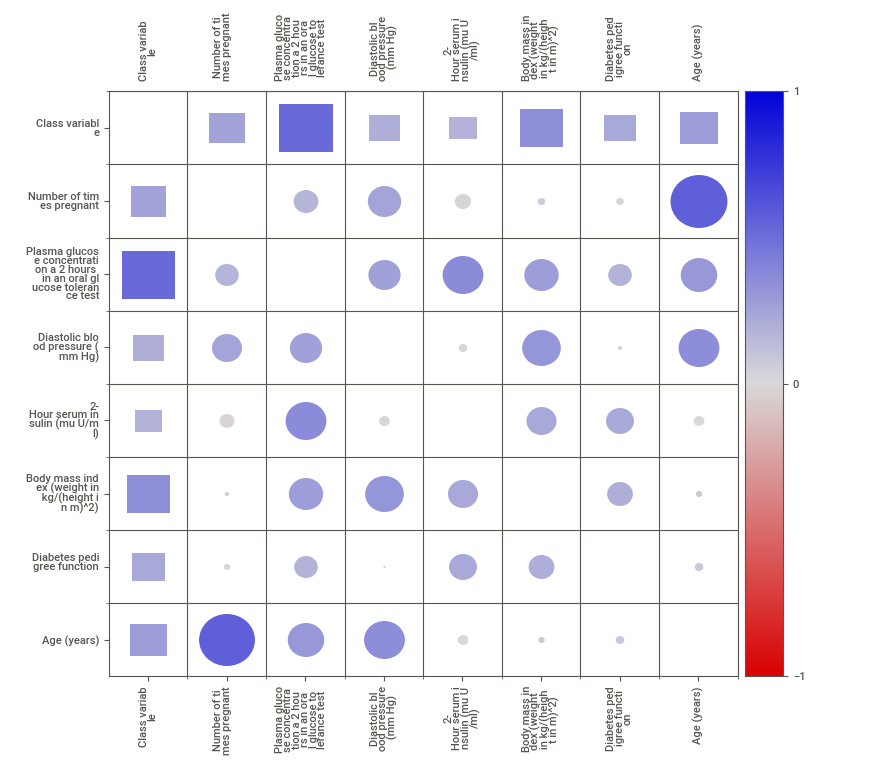
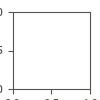

In [3]:
import sweetviz as sv

reporteinicial = sv.analyze(datainicial, target_feat='Class variable')
reporteinicial.show_notebook()
# reporte.show_html('mi_reporteinicial.html')  # Guarda el reporte

In [4]:
from pycaret.datasets import get_data
data = get_data('diabetes')
print('Dimensiones de la tabla:', data.shape)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable
0,6,148,72,0,33.6,0.627,50,1
1,1,85,66,0,26.6,0.351,31,0
2,8,183,64,0,23.3,0.672,32,1
3,1,89,66,94,28.1,0.167,21,0
4,0,137,40,168,43.1,2.288,33,1


Dimensiones de la tabla: (753, 8)


**Diccionario de variables**
1. **Número de embarazos**: Número de veces que la paciente ha estado embarazada.
2. **Glucosa en plasma**: Concentración de glucosa en plasma a 2 horas en una prueba de tolerancia a la glucosa oral.
3. **Presión arterial diastólica**: Presión arterial diastólica (mm Hg).
4. **Grosor del pliegue cutáneo del tríceps**: Grosor del pliegue de la piel del tríceps (mm).
5. **Insulina sérica de 2 horas**: Insulina sérica a las 2 horas (mu U/ml).
6. **Índice de masa corporal (IMC)**: Peso en kg/(altura en m)^2.
7. **Función del pedigrí de la diabetes**: Función que representa la influencia genética esperada de los familiares y la historia de la enfermedad.
8. **Edad**: Edad del paciente (años).
9. **Clase**: Variable de resultado, indica si la paciente tiene diabetes (1) o no (0).



## Limpieza de datos (ver descripción y justificación anexa en word)

Resumen de criterios de limpieza de datos:

1. Eliminar 4 registros con glucosa e insulina en cero.
2. El dato de insulina seríca en 23, 21 años de edad, glucosa en cero, 27,7 indce de masa corporal y 1 embarazo, cambiar la glucosa por el valor promedio de  105 calculado deun grupo similiar de mujeres.
3. Presión arterial diastólica con varlor cero, se corregirá por el valor promedio de 69.
4. Espesor de la piel en el triceps, esta variable se elimina del dataframe.
5. En Indice de masa corporal con valor en cero, se eliminarán estos registros.








In [5]:
# Filtrar los registros donde glucosa y insulina están en cero
mask = (
    (data["Plasma glucose concentration a 2 hours in an oral glucose tolerance test"] == 0) &
    (data["2-Hour serum insulin (mu U/ml)"] == 0)
)

n = mask.sum()
print(f"Se encontraron {n} filas con glucosa=0 e insulina=0")

# Eliminar esas filas
data = data[~mask].copy()

print("Dimensiones finales:", data.shape)

Se encontraron 0 filas con glucosa=0 e insulina=0
Dimensiones finales: (753, 8)


In [6]:
#2.l dato de insulina seríca en 23 + 21 años de edad + glucosa en cero + 27,7 indce de masa corporal + 1 embarazo, cambiar la glucosa por el valor promedio de  105 calculado deun grupo similiar de mujeres.
# Filtro del registro a corregir
mask = (
    (data["2-Hour serum insulin (mu U/ml)"] == 23) &
    (data["Age (years)"] == 21) &
    (data["Plasma glucose concentration a 2 hours in an oral glucose tolerance test"] == 0) &
    (data["Body mass index (weight in kg/(height in m)^2)"] == 27.7) &
    (data["Number of times pregnant"] == 1)
)

# Verifica si existe
if mask.any():
    idx = data.index[mask][0]
    data.loc[idx, "Plasma glucose concentration a 2 hours in an oral glucose tolerance test"] = 105
    print("Registro corregido:")
    print(data.loc[idx])
else:
    print("No se encontró el registro solicitado.")


No se encontró el registro solicitado.


In [7]:
# Corregir presión arterial diastólica con valor cero
col = "Diastolic blood pressure (mm Hg)"

n_ceros = (data[col] == 0).sum()
print(f"Se encontraron {n_ceros} valores cero en {col}")

# Reemplazar los ceros por el valor promedio indicado
data.loc[data[col] == 0, col] = 69

print("Valores cero corregidos.")
print(data[col].describe())

Se encontraron 0 valores cero en Diastolic blood pressure (mm Hg)
Valores cero corregidos.
count    753.000000
mean      72.276228
std       12.156041
min       24.000000
25%       64.000000
50%       72.000000
75%       80.000000
max      122.000000
Name: Diastolic blood pressure (mm Hg), dtype: float64


In [8]:
col = "Triceps skin fold thickness (mm)"

if col in data.columns:
    data = data.drop(columns=[col])
    print(f"Columna eliminada: {col}")
else:
    print(f"La columna {col} no existe en el DataFrame.")

La columna Triceps skin fold thickness (mm) no existe en el DataFrame.


In [9]:
# Eliminar registros con IMC en cero
col = "Body mass index (weight in kg/(height in m)^2)"

n_ceros = (data[col] == 0).sum()
print(f"Se encontraron {n_ceros} registros con IMC = 0")

data = data[data[col] != 0].copy()

print("Dimensiones finales:", data.shape)

Se encontraron 0 registros con IMC = 0
Dimensiones finales: (753, 8)


In [10]:
data.to_csv("diabetes.csv", index=False)
print("Archivo exportado: diabetes.csv")

Archivo exportado: diabetes.csv


## 2. Análisis Descriptivo Exploratorio (EDA)

Es obligatorio entender los datos antes que cualquier otra cosa. Responder preguntas como:
1. Las variables tiene valores nulos?
2. Cuál es el comportamiento de cada variable? Tienen sesgo?
3. Cómo se relaciona cada variable frente a la variable objetivo?
4. Cómo se relacionan entre sí las variables? Mapa de correlación

                                             |          | [  0%]   00:00 -> (? left)


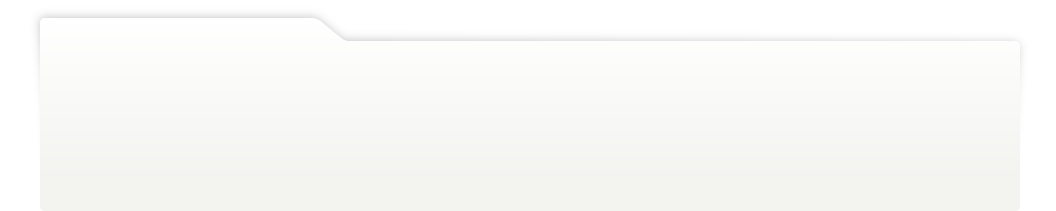
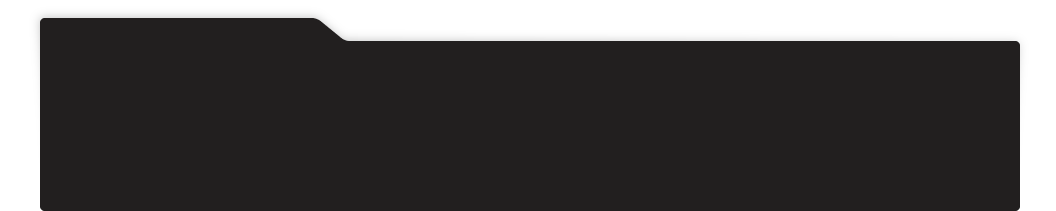
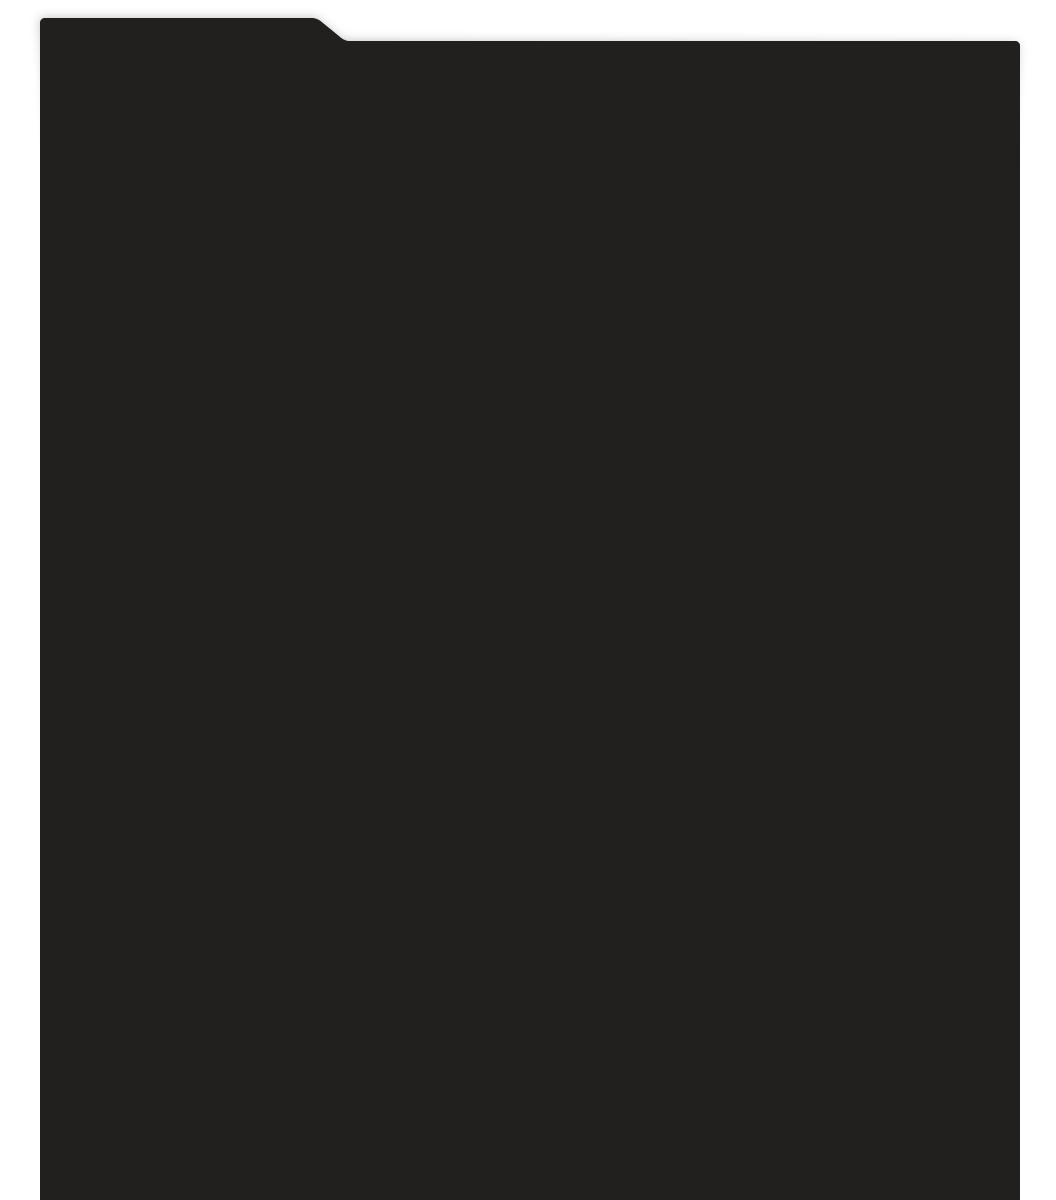
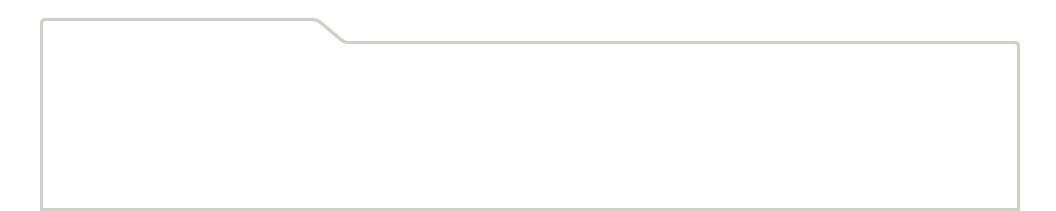
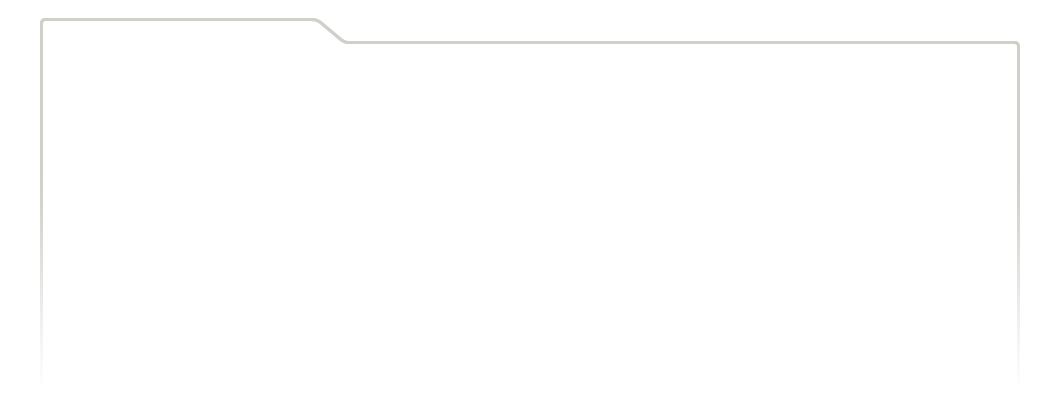
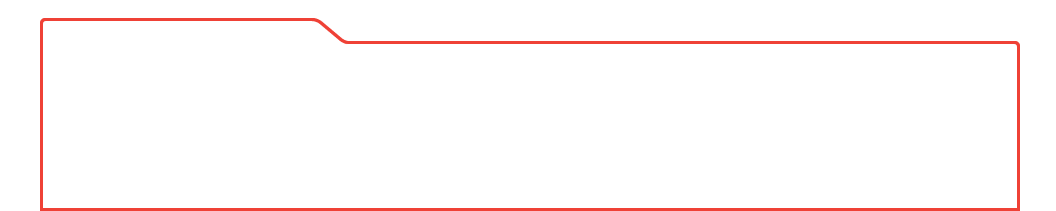
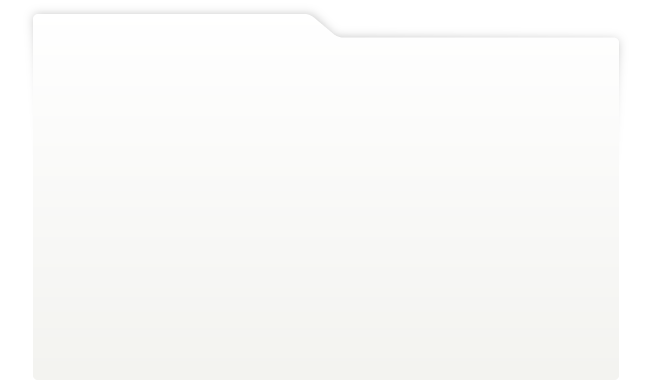
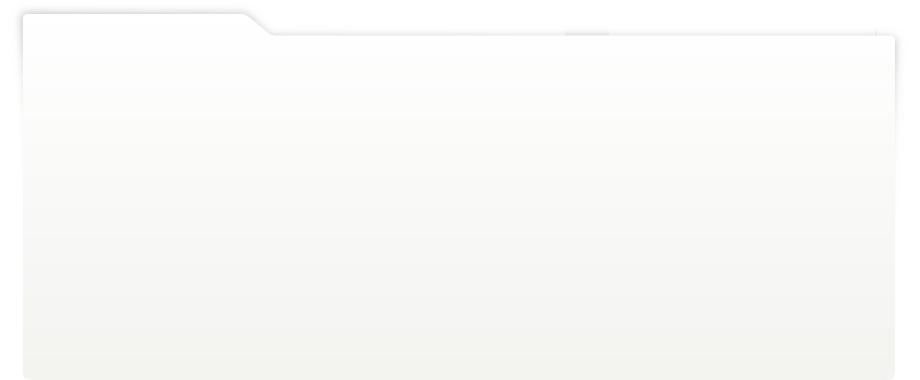
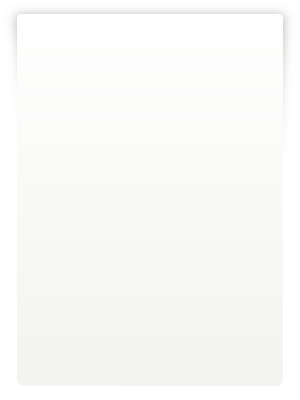
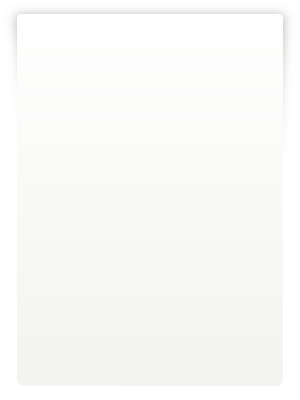
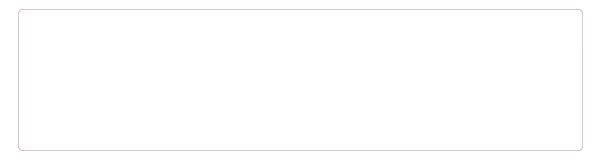
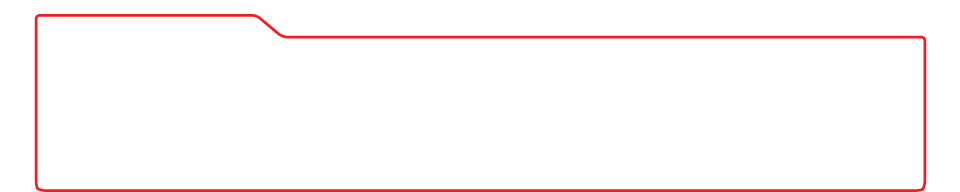
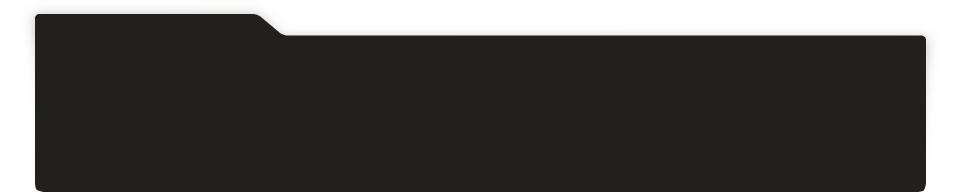
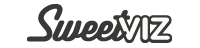
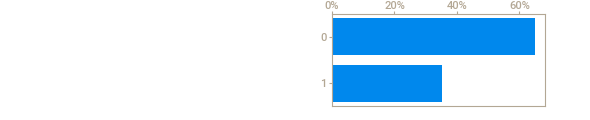
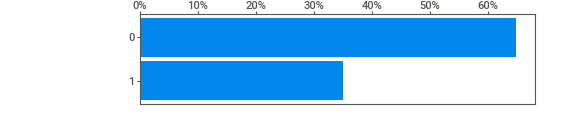
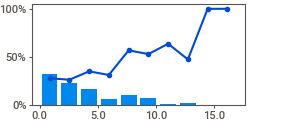
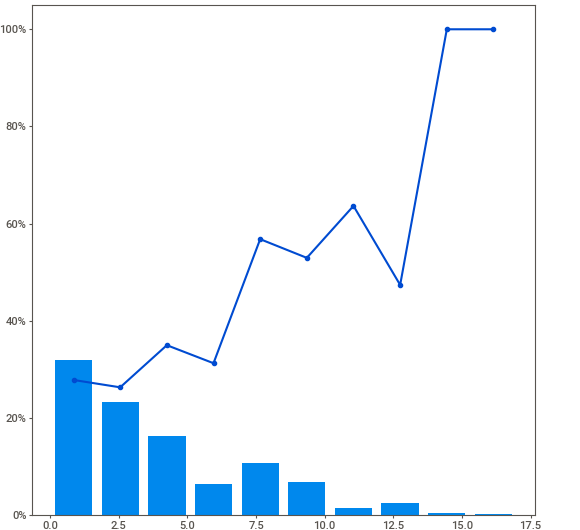
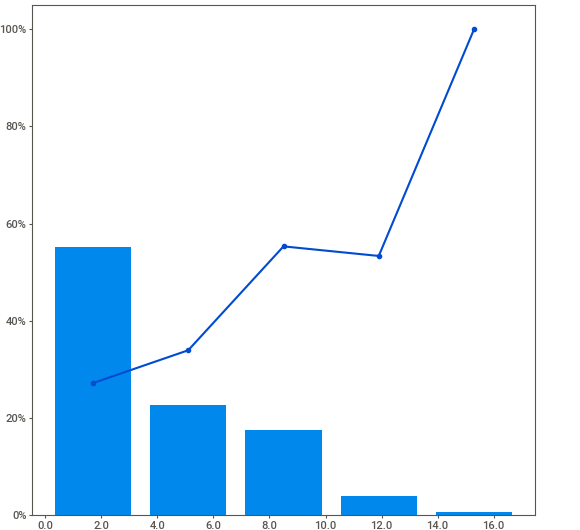
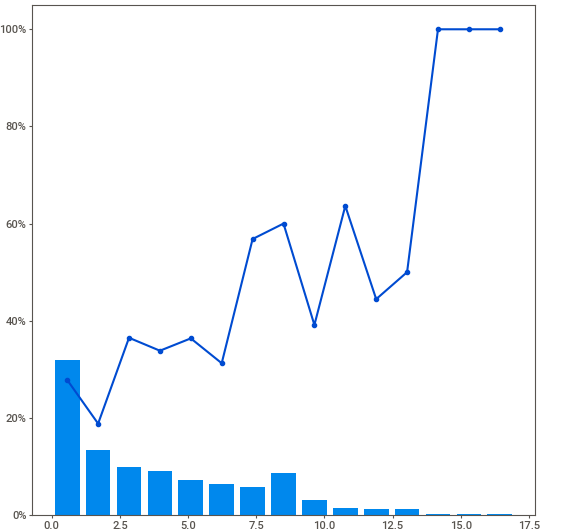
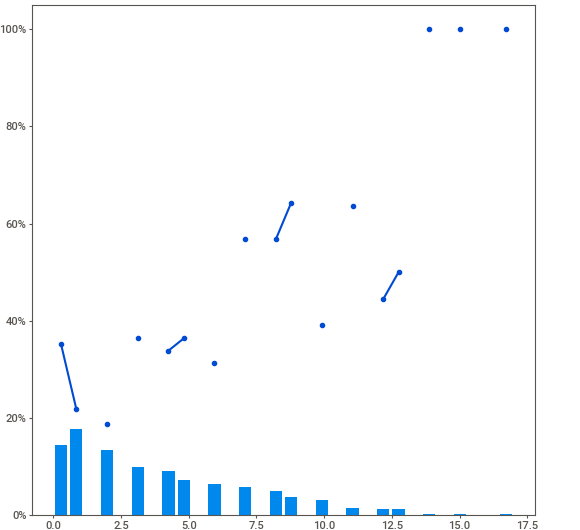
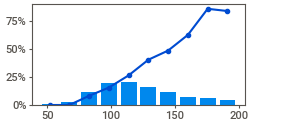
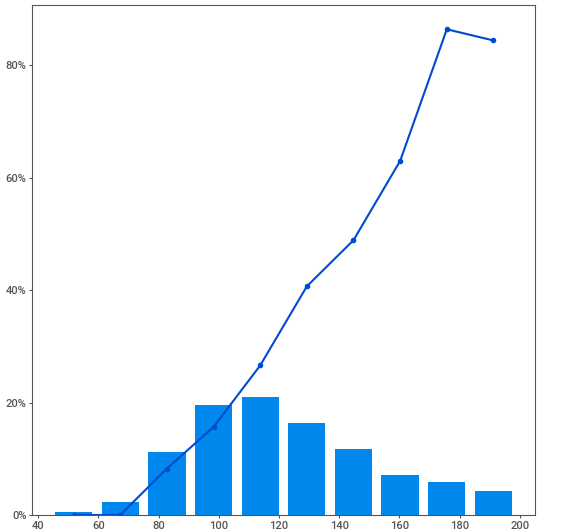
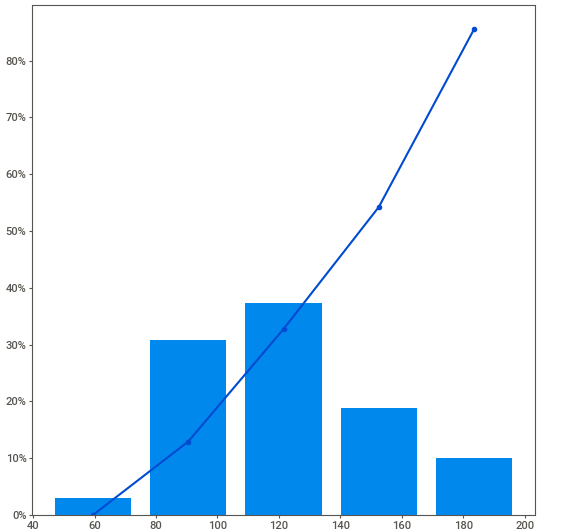
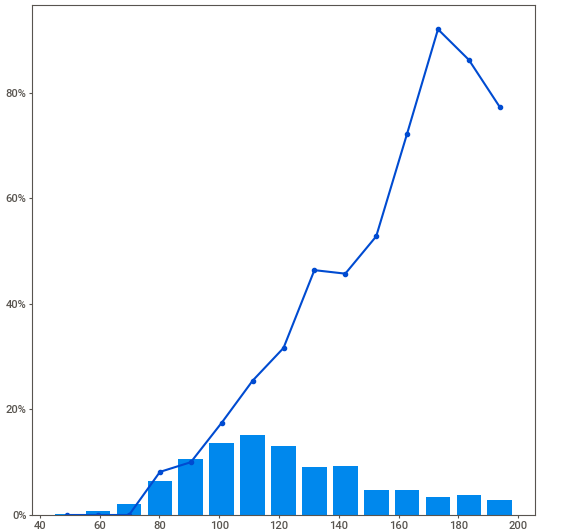
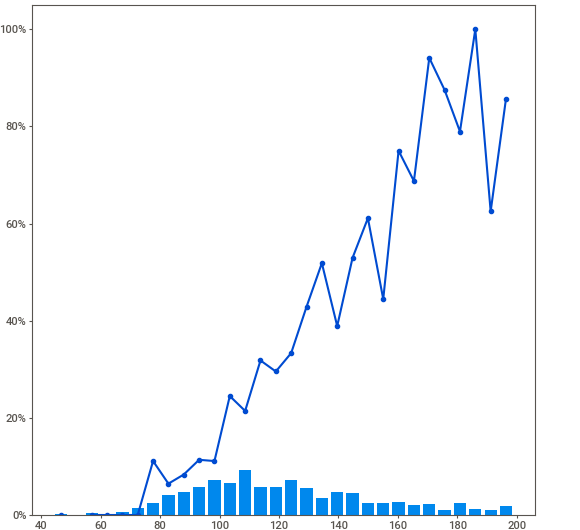
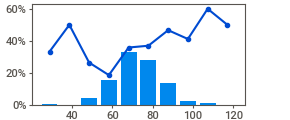
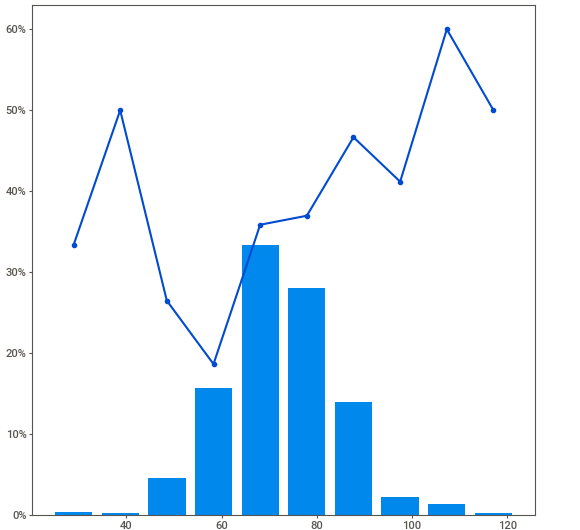
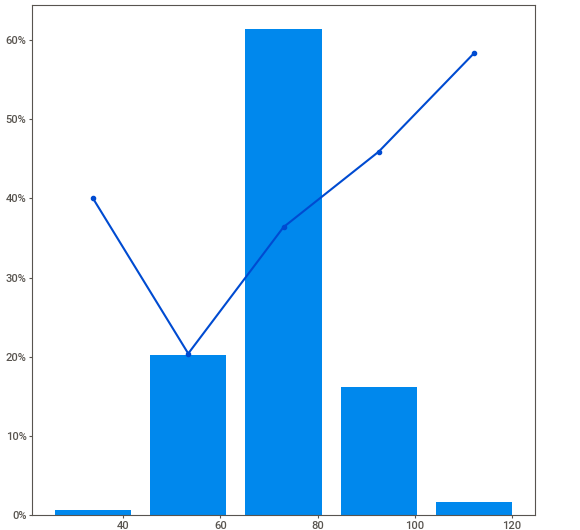
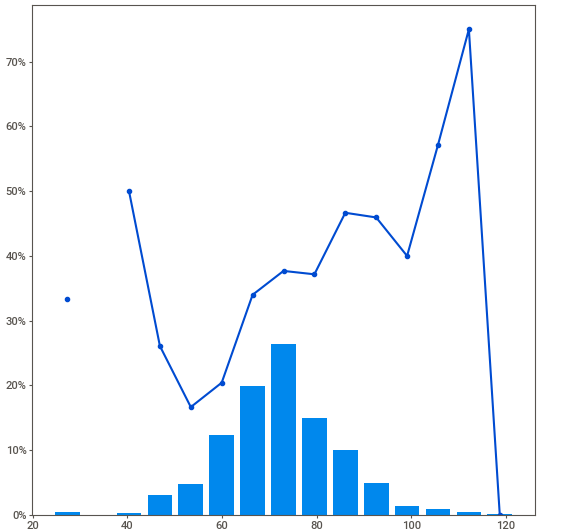
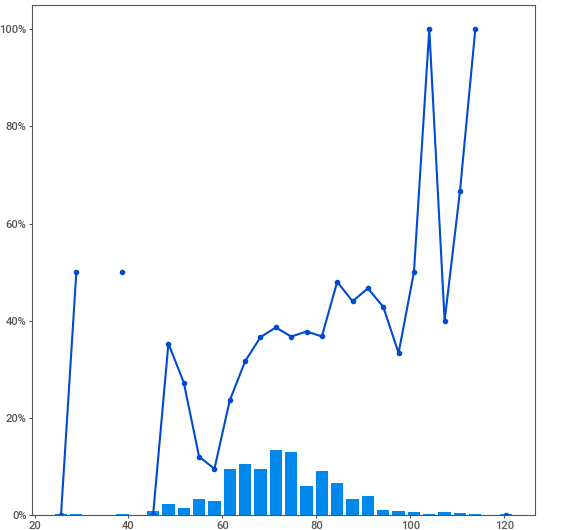
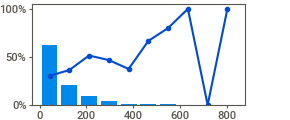
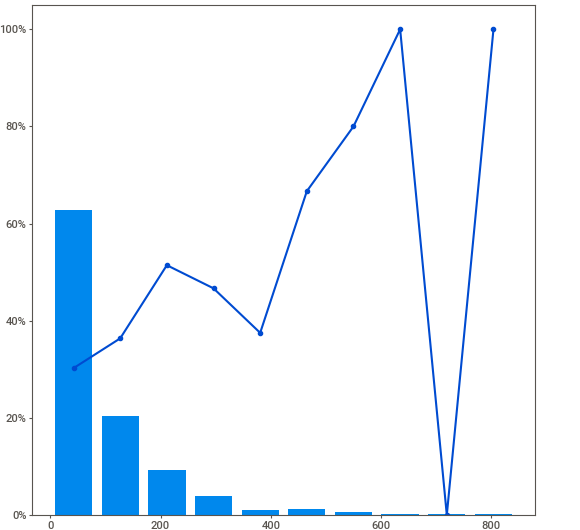
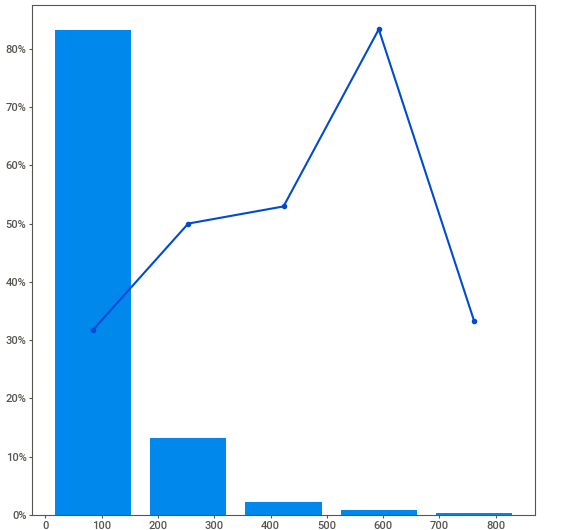
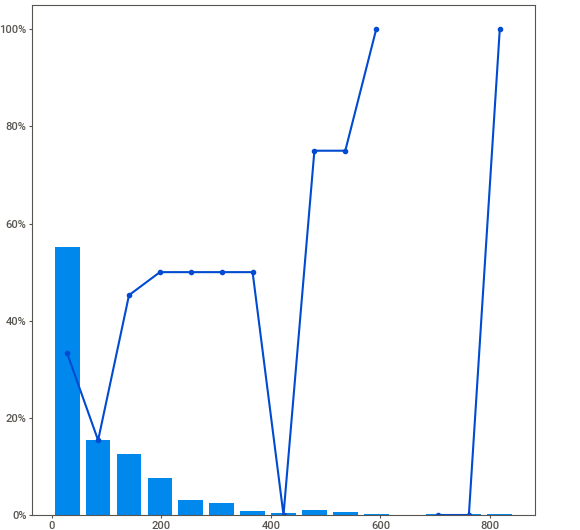
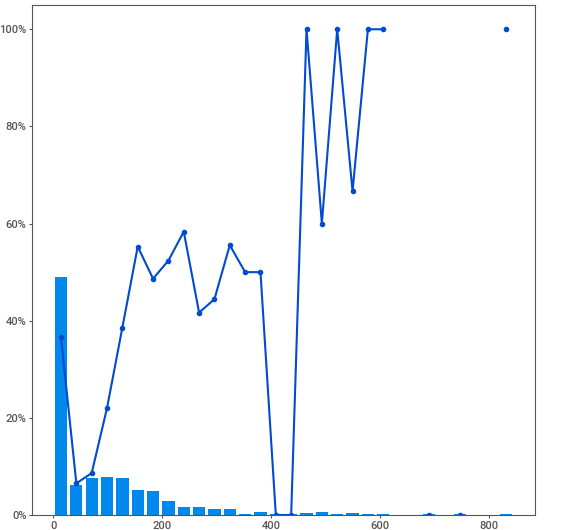
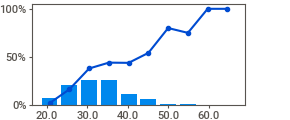
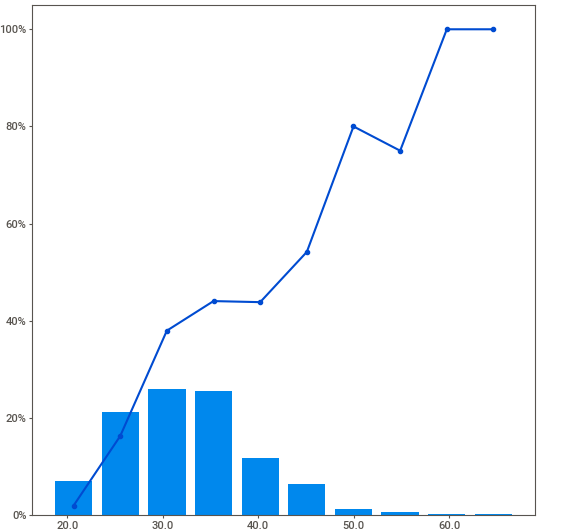
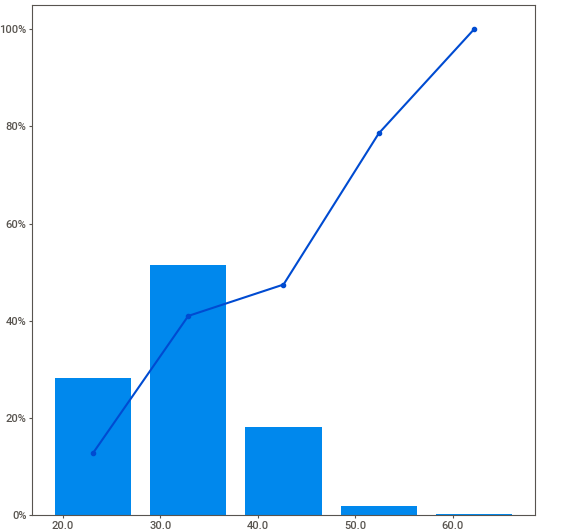
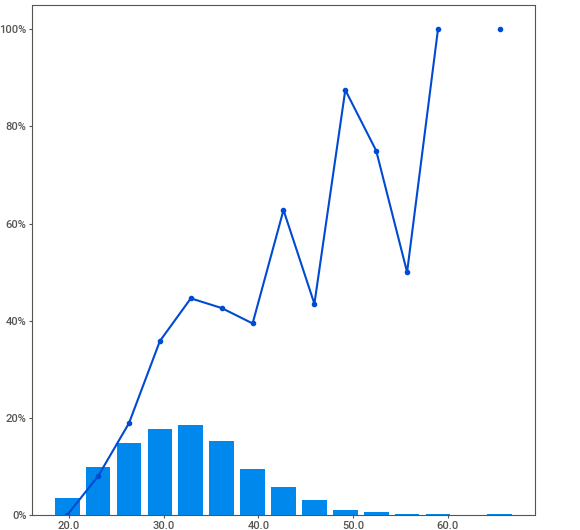
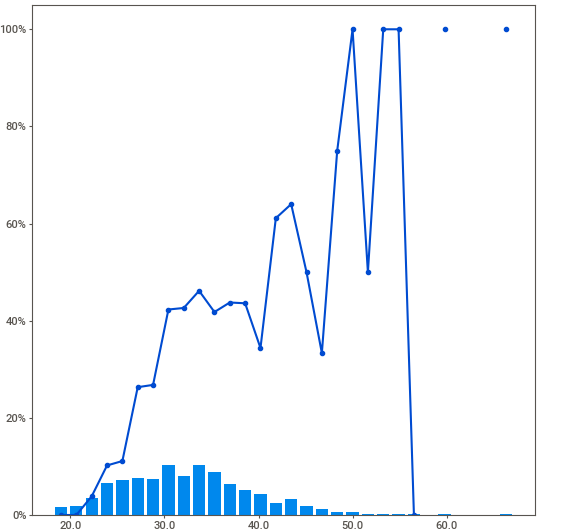
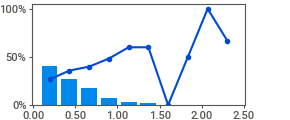
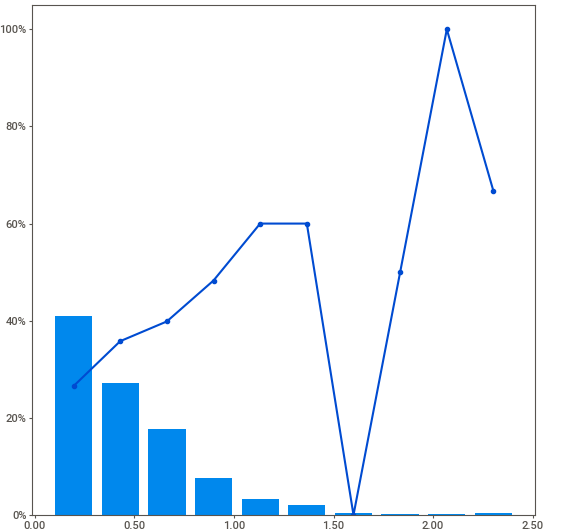
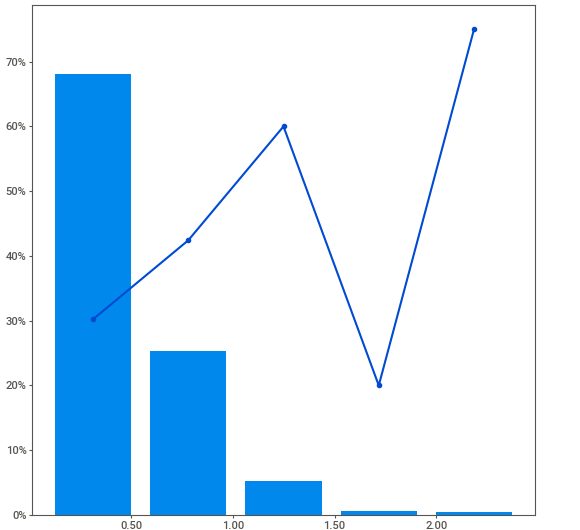
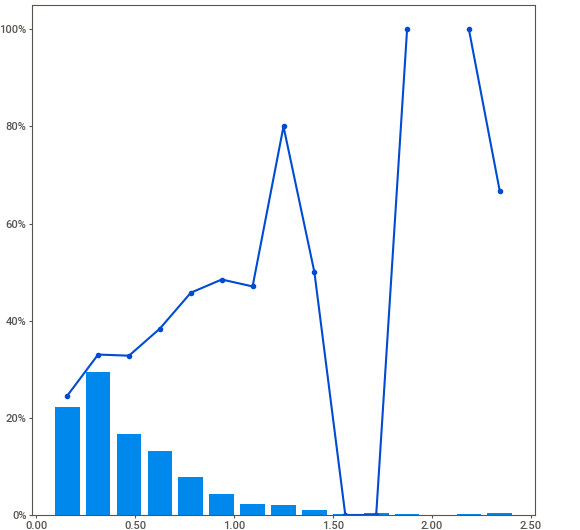
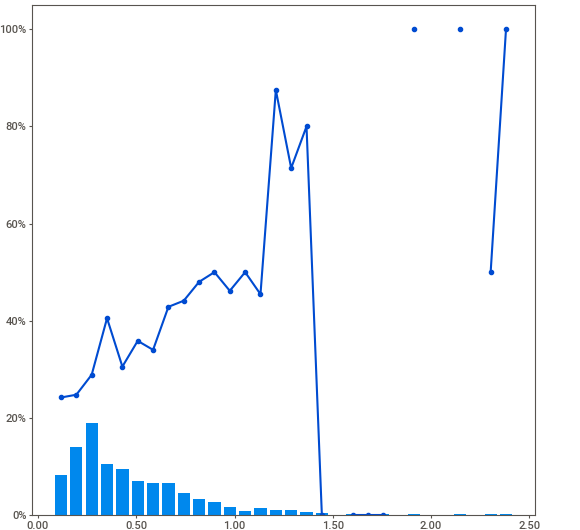
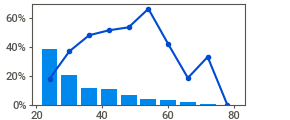
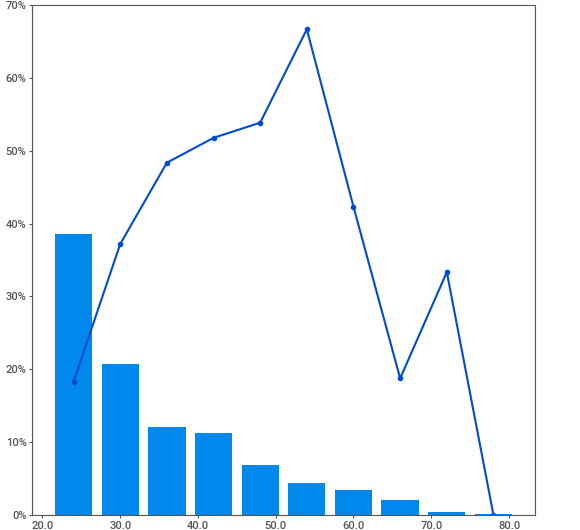
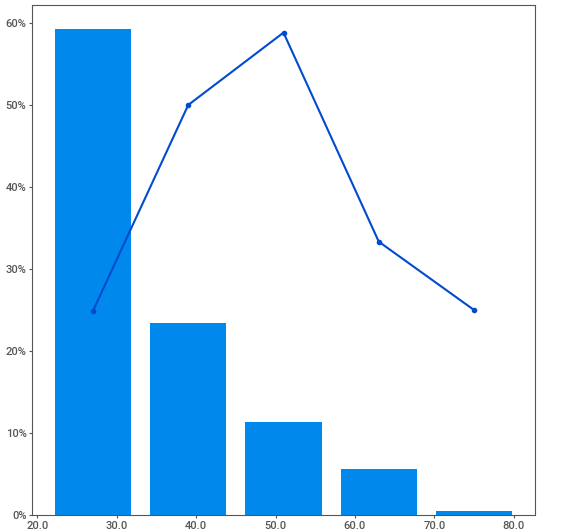
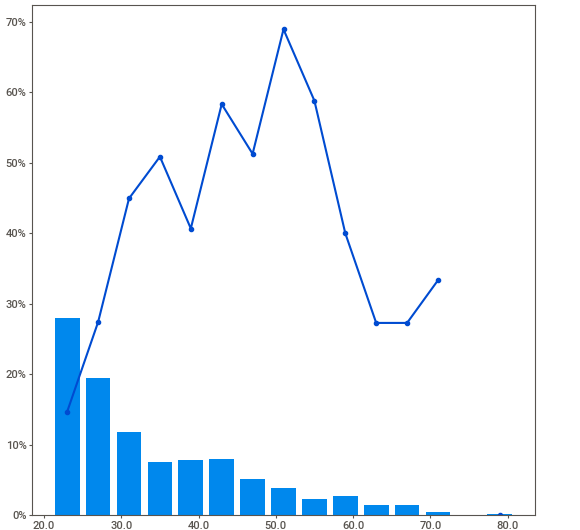
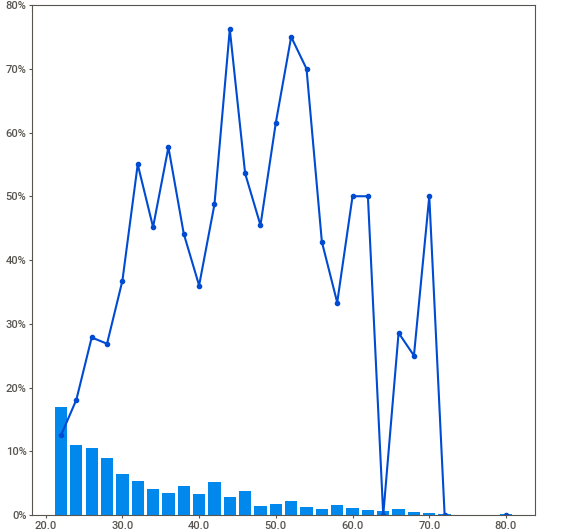
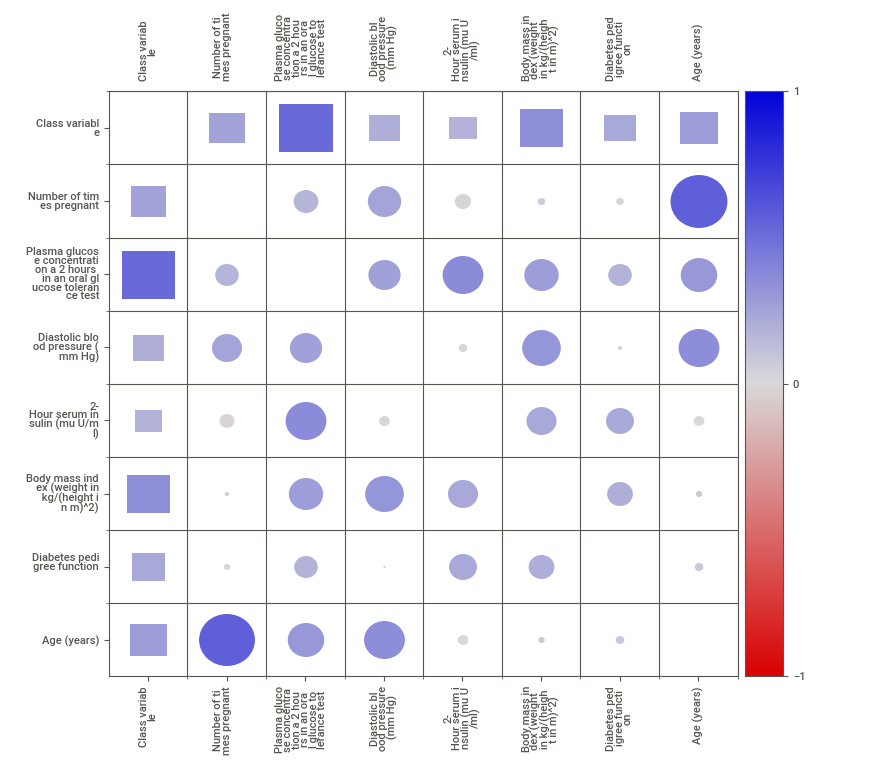
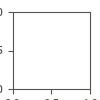

In [11]:
import sweetviz as sv

reporte = sv.analyze(data, target_feat='Class variable')
reporte.show_notebook()
# reporte.show_html('mi_reporte.html')  # Guarda el reporte

**Análisis**:

Se observa que la tabla no tiene valores nulos, la variable objetivo tiene un ligero desbalance (65% de los pacientes no tienen diabetes frente a 35% que si lo tienen). La variable objetivo se relaciona más con las variables: concentración de glucosa, índice de masa corporal, edad y número de veces embarazada.

En seguida el análisis específico para cada variable explicativa de la diabetes:

Nota: Ver archivo de word anexo al envio de la actividad.

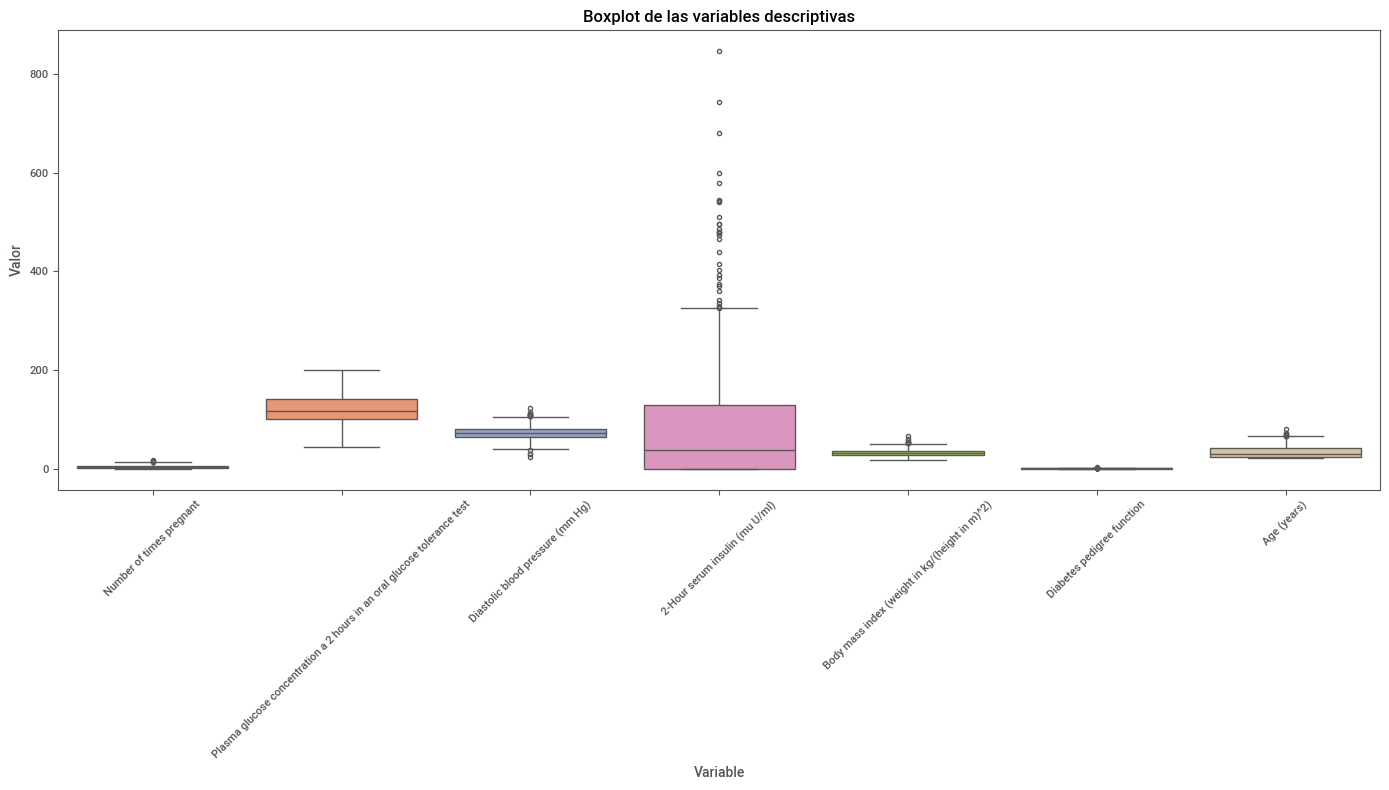

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Variables descriptivas (7 columnas sin la variable objetivo)
features = [
    "Number of times pregnant",
    "Plasma glucose concentration a 2 hours in an oral glucose tolerance test",
    "Diastolic blood pressure (mm Hg)",
    "2-Hour serum insulin (mu U/ml)",
    "Body mass index (weight in kg/(height in m)^2)",
    "Diabetes pedigree function",
    "Age (years)"
]

# Verifica que existan en el DataFrame
missing = [c for c in features if c not in data.columns]
if missing:
    raise ValueError(f"Faltan columnas: {missing}")

# Formato largo para boxplot
df_box = data[features].melt(var_name="Variable", value_name="Valor")

# Gráfico
plt.figure(figsize=(14, 8))
sns.boxplot(data=df_box, x="Variable", y="Valor", palette="Set2")
plt.title("Boxplot de las variables descriptivas")
plt.xticks(rotation=45)
plt.ylabel("Valor")
plt.xlabel("Variable")
plt.tight_layout()
plt.show()

### Ejercicio 1 (10 puntos)

> a. Continúe el análisis univariado para las demás variables

Nota: Ver archivo de word anexo al envio de la actividad.

> b. Realice un análisis de acuerdo a la correlación

Nota: Ver archvivo de word anexo al envio de la actividad con el análisis del sesgo y la correlación.



Escriba su análisis aquí

## 3. Configuración PyCaret

Esta función inicializa el entorno de entrenamiento y crea la canalización de transformación. La función de configuración debe llamarse antes de ejecutar cualquier otra función. Toma dos parámetros obligatorios: `data` y `target`. Todos los demás parámetros son opcionales.

Puede especificar el session_id para que la división de los datos en entrenamiento y testeo permanezca fijo.

In [13]:
from pycaret import classification

s = classification.setup(
    data,
    target = 'Class variable',
    session_id=1234,
    normalize=True
)

,Description,Value
0,Session id,1234
1,Target,Class variable
2,Target type,Binary
3,Original data shape,"(753, 8)"
4,Transformed data shape,"(753, 8)"
5,Transformed train set shape,"(527, 8)"
6,Transformed test set shape,"(226, 8)"
7,Numeric features,7
8,Preprocess,True
9,Imputation type,simple


Cuando se ejecuta la configuración, el algoritmo de inferencia de PyCaret inferirá automáticamente los tipos de datos para todas las variables en función de ciertas propiedades.

El tipo de datos debe inferirse correctamente, pero no siempre es así.

Asegurarse de que los tipos de datos sean correctos es realmente importante en PyCaret, ya que realiza automáticamente múltiples tareas de preprocesamiento específicas del tipo que son imprescindibles para los modelos de aprendizaje automático.


Alternativamente, también puede usar los parámetros `numeric_features` y `categorical_features` en la configuración para predefinir los tipos de datos.

### Ejercicio 2 (10 puntos)

1. Cuál es el tamaño de los datos de entrenamiento y testeo?
2. Consulte para qué sirve dividir los datos de esta manera?


Escriba la respuesta a las dos preguntas aquí

1. Tamaño de los datos:

Conjunto de entrenamiento (Train): 527 filas y 8 columnas.

Conjunto de prueba (Test): 226 filas y 8 columnas.

2. Utilidad de dividir los datos:

Evaluar la generalización: Permite probar el modelo con datos totalmente nuevos que no ha visto antes, simulando su comportamiento real en producción.

Prevenir el sobreajuste (overfitting): Evita que el algoritmo simplemente "memorice" las respuestas del conjunto de entrenamiento, asegurando que aprenda patrones reales aplicables a casos futuros.



In [14]:
# Para ver como quedaron transformados los datos, use esto:
X_train = classification.get_config('X_train_transformed')
X_train.head(5)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years)
587,-0.818695,-0.461272,1.206940,-0.713725,-0.794282,-0.221635,-0.777783
406,-0.224817,1.644669,0.890729,3.213561,0.426626,-0.687436,-0.943698
661,1.259877,-1.012057,0.732624,-0.713725,0.412429,0.391780,2.872336
397,0.072122,-0.234479,-0.057902,-0.713725,-0.538744,-0.300362,1.047276
110,0.072122,0.769894,1.523150,-0.713725,-0.212222,0.234326,2.291635


In [15]:
# Para ver como quedaron transformados los datos, use esto:
X_test = classification.get_config('X_test_transformed')
X_test.head(5)

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years)
245,-0.521756,0.219109,0.890729,-0.713725,-0.666513,-0.602149,-0.528912
30,-0.224817,1.158683,0.258308,1.316201,-0.155435,1.257778,-0.445954
658,-0.818695,-0.752864,-1.164638,-0.713725,-1.035625,0.273690,-1.026655
423,-0.521756,0.543100,0.179256,-0.713725,-1.007231,-0.985943,-0.362997
537,-0.818695,-0.202079,-0.216007,-0.713725,-0.751693,-0.864572,-1.026655


In [16]:
# Exportar a CSV
X_train.to_csv('x_train.csv', index=False)
X_test.to_csv('x_test.csv', index=False)

print("Archivos exportados:")
print(" - x_train.csv")
print(" - x_test.csv")

Archivos exportados:
 - x_train.csv
 - x_test.csv


In [17]:
# Obtener los datos transformados
X_train = classification.get_config('X_train_transformed')
X_test = classification.get_config('X_test_transformed')

# Resumen estadístico de X_train
print("Resumen de X_train")
print(X_train.describe().T)

# Resumen estadístico de X_test
print("\nResumen de X_test")
print(X_test.describe().T)

Resumen de X_train
                                                    count          mean  \
Number of times pregnant                            527.0 -7.078462e-17   
Plasma glucose concentration a 2 hours in an or...  527.0  9.269414e-17   
Diastolic blood pressure (mm Hg)                    527.0 -1.516813e-16   
2-Hour serum insulin (mu U/ml)                      527.0  3.033626e-17   
Body mass index (weight in kg/(height in m)^2)      527.0 -2.696557e-17   
Diabetes pedigree function                          527.0  5.393114e-17   
Age (years)                                         527.0  3.370696e-17   

                                                        std       min  \
Number of times pregnant                            1.00095 -1.115633   
Plasma glucose concentration a 2 hours in an or...  1.00095 -2.534815   
Diastolic blood pressure (mm Hg)                    1.00095 -3.378111   
2-Hour serum insulin (mu U/ml)                      1.00095 -0.713725   
Body mass index

In [18]:
display(X_train.describe().T)


,count,mean,std,min,25%,50%,75%,max
Number of times pregnant,527.0,-7.078462e-17,1.00095,-1.115633,-0.818695,-0.224817,0.665999,3.932326
Plasma glucose concentration a 2 hours in an oral glucose tolerance test,527.0,9.269414e-17,1.00095,-2.534815,-0.720465,-0.169680,0.656497,2.487046
Diastolic blood pressure (mm Hg),527.0,-1.516813e-16,1.00095,-3.378111,-0.690323,-0.057902,0.574519,3.894728
2-Hour serum insulin (mu U/ml),527.0,3.033626e-17,1.00095,-0.713725,-0.713725,-0.365737,0.425520,6.295734
Body mass index (weight in kg/(height in m)^2),527.0,-2.696557e-17,1.00095,-2.057780,-0.730398,-0.041862,0.632476,4.884359
Diabetes pedigree function,527.0,5.393114e-17,1.00095,-1.258208,-0.731720,-0.228195,0.508231,5.971561
Age (years),527.0,3.370696e-17,1.00095,-1.026655,-0.777783,-0.362997,0.632490,3.950781


In [19]:
display(X_test.describe().T)

,count,mean,std,min,25%,50%,75%,max
Number of times pregnant,226.0,0.089202,1.003997,-1.115633,-0.818695,-0.224817,0.888703,3.041510
Plasma glucose concentration a 2 hours in an oral glucose tolerance test,226.0,-0.034350,0.969144,-2.113626,-0.752864,-0.104882,0.543100,2.454647
Diastolic blood pressure (mm Hg),226.0,-0.120165,0.856753,-3.852426,-0.690323,-0.216007,0.416414,2.629886
2-Hour serum insulin (mu U/ml),226.0,-0.134479,0.851656,-0.713725,-0.713725,-0.552159,0.228741,5.450622
Body mass index (weight in kg/(height in m)^2),226.0,-0.116614,0.938035,-2.057780,-0.801381,-0.155435,0.384036,3.791221
Diabetes pedigree function,226.0,0.057423,1.253266,-1.277889,-0.739921,-0.418452,0.600899,6.404560
Age (years),226.0,-0.021991,0.900845,-1.026655,-0.694826,-0.362997,0.632490,3.038251


### Ejercicio 3 (10 puntos)

1. Verifique que las variables de entrenamiento (X_train) quedaron correctamente normalizadas. Su media debería ser cero y la varianza 1
2. Por qué no sucede lo mismo con X_test. Qué puede estar pasando?

In [20]:
# ------------------------------------------
# Verifique media 0 y var 1 para X_train (aprox. entre 1 a 5 líneas de código)

# ------------------------------------------

## Verificación de X_train: 
Sí, las variables de entrenamiento están correctamente normalizadas. Como se observa en la primera tabla de la imagen (X_train.describe().T), la media (mean) de cada variable es un número extremadamente cercano a cero,  y la desviación estándar (std) es exactamente 1.0 en todas ellas (por ende, la varianza, que es el cuadrado de la desviación estándar)

In [21]:
# ------------------------------------------
# calcule media y var para X_test (aprox. entre 1 a 5 líneas de código)

# ------------------------------------------

## Comportamiento en X_test: 

Es completamente normal que la media y la varianza de X_test no sean exactamente cero y uno. Esto sucede por una regla de Machine Learning para evitar el data leakage (fuga de datos):

Los parámetros de normalización (la media y la desviación estándar) se calculan exclusivamente utilizando los datos del conjunto de entrenamiento.

Esos mismos valores calculados en el entrenamiento se utilizan luego para transformar o escalar el conjunto de prueba (X_test).

Como el conjunto de prueba contiene datos nuevos e independientes (con una distribución ligeramente distinta), al aplicarles la media y la desviación estándar del entrenamiento, el resultado en el test no quedará perfectamente centrado en cero ni con varianza uno, lo cual es el comportamiento esperado y correcto.

Realice su análisis aquí

## 4. Comparar modelos

Esta función entrena y evalúa el rendimiento de todos los estimadores (modelos) disponibles en la biblioteca de modelos mediante validación cruzada.

El resultado de esta función es una tabla de puntuación con puntuaciones medias validadas de forma cruzada. Se puede acceder a las métricas evaluadas durante CV mediante la función `get_metrics`. Las métricas personalizadas se pueden agregar o eliminar mediante las funciones `add_metric` y `remove_metric`.

In [22]:
mejor_modelo_auc = classification.compare_models(sort='AUC')

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.7628,0.8438,0.5944,0.6891,0.6362,0.4622,0.4664,0.2290
lr,Logistic Regression,0.7761,0.8419,0.5833,0.7319,0.6434,0.4844,0.4951,0.5790
lda,Linear Discriminant Analysis,0.7761,0.8410,0.5944,0.7275,0.6487,0.4877,0.4970,0.0870
ridge,Ridge Classifier,0.7704,0.8409,0.5725,0.7250,0.6328,0.4705,0.4819,0.0440
gbc,Gradient Boosting Classifier,0.7667,0.8339,0.6211,0.6960,0.6503,0.4769,0.4830,0.2840
rf,Random Forest Classifier,0.7646,0.8326,0.5991,0.6910,0.6392,0.4663,0.4708,0.1850
lightgbm,Light Gradient Boosting Machine,0.7609,0.8220,0.6488,0.6712,0.6550,0.4732,0.4775,0.6980
qda,Quadratic Discriminant Analysis,0.7438,0.8217,0.5620,0.6641,0.6038,0.4177,0.4241,0.0410
nb,Naive Bayes,0.7515,0.8173,0.6173,0.6565,0.6302,0.4457,0.4500,0.0390
knn,K Neighbors Classifier,0.7456,0.8088,0.5883,0.6538,0.6158,0.4273,0.4313,0.0740


In [23]:
print(mejor_modelo_auc)

ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                     criterion='gini', max_depth=None, max_features='sqrt',
                     max_leaf_nodes=None, max_samples=None,
                     min_impurity_decrease=0.0, min_samples_leaf=1,
                     min_samples_split=2, min_weight_fraction_leaf=0.0,
                     monotonic_cst=None, n_estimators=100, n_jobs=-1,
                     oob_score=False, random_state=1234, verbose=0,
                     warm_start=False)


## 5. Analizar el mejor modelo

Esta función analiza el rendimiento de un modelo entrenado en los datos de testeo

In [24]:
classification.evaluate_model(mejor_modelo_auc)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

### Ejercicio 4 (10 puntos)

El método anterior nos permite obtener el mejor modelo, sin embargo algunas veces necesitamos tomar el modelo por su simplicidad más que por su rendimiento. Para esto debemos utilizar el método `classification.create_model`.

Por ejemplo para el modelo `randomforest` utilizamos:
`model_rf = classification.create_model('rf')`

1. Del listado tome el modelo de regresión logística y asígnelo a `modelo_regresion_logistica`
2. Luego evalúe con el botón `Learning Curve` frente al modelo `mejor_modelo` realizado anteriormente. Consulte el significado de esta curva y SOLO TENIENDO EN CUENTA ESTO, explique cual modelo es considerado mejor.

Ver análisis comparatativo de "Learning Curve' que se presenta más adelante, después de generar el modelo de regresión logística.

Logistic Regression (lr) es la opción ideal por la simplicidad y la interpretabilidad, destacando además por un excelente rendimiento al empatar con la mayor precisión global (Accuracy de 0.7761).

Razones de su simplicidad:

Interpretabilidad directa: Permite entender con facilidad el impacto y la dirección de cada variable sobre la probabilidad de la clase objetivo a través de sus coeficientes.

Menor complejidad computacional: Requiere pocos recursos y un tiempo de ejecución bajo en comparación con modelos de ensamblaje avanzados como Extra Trees o Gradient Boosting.

Fórmula matemática clara: Se basa en una relación lineal acoplada a una función sigmoide, lo que reduce el riesgo de sobreajuste (overfitting).

In [25]:
from pycaret import classification

# Asegúrate de que exista este DataFrame
# data = ...  # tu dataframe ya limpio

s = classification.setup(
    data=data,
    target='Class variable',
    session_id=1234,
    normalize=True
)

,Description,Value
0,Session id,1234
1,Target,Class variable
2,Target type,Binary
3,Original data shape,"(753, 8)"
4,Transformed data shape,"(753, 8)"
5,Transformed train set shape,"(527, 8)"
6,Transformed test set shape,"(226, 8)"
7,Numeric features,7
8,Preprocess,True
9,Imputation type,simple


In [26]:
# ------------------------------------------
# 1. Cree el modelo y evalúelo (2 líneas de código)

# ------------------------------------------

from pycaret import classification

# Crear el modelo de regresión logística
modelo_regresion_logistica = classification.create_model('lr')

# Evaluar el modelo con gráficos y métricas
classification.evaluate_model(modelo_regresion_logistica)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7170,0.7460,0.5000,0.6000,0.5455,0.3424,0.3454
1,0.7736,0.8397,0.5556,0.7143,0.6250,0.4664,0.4740
2,0.8302,0.8731,0.6842,0.8125,0.7429,0.6175,0.6226
3,0.8113,0.8994,0.6316,0.8000,0.7059,0.5698,0.5784
4,0.7736,0.8344,0.4737,0.8182,0.6000,0.4573,0.4906
5,0.8302,0.9087,0.7895,0.7500,0.7692,0.6350,0.6356
6,0.6981,0.7724,0.4211,0.6154,0.5000,0.2945,0.3054
7,0.8462,0.8742,0.6111,0.9167,0.7333,0.6312,0.6568
8,0.7500,0.8807,0.5000,0.6923,0.5806,0.4091,0.4201


interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [27]:
mejor_modelo = mejor_modelo_auc  # Para usar el modelo con mejor AUC
# mejor_modelo = modelo_regresion_logistica  # Descomente para usar el modelo de regresión logística

## Análiis de Learning Curve

Basándonos estrictamente en el significado de la Curva de Aprendizaje (Learning Curve) —la cual evalúa cómo evoluciona el puntaje del modelo tanto en el conjunto de entrenamiento como en el de validación cruzada a medida que se le proporcionan más datos— y comparando el modelo de Regresión Logística con el mejor modelo anterior (Extra Trees Classifier):

Significado de la curva: Una curva de aprendizaje ideal muestra que el puntaje de entrenamiento y el de validación cruzada se mantienen altos y convergen de manera cercana, lo que indica que el modelo generaliza bien sin sobreajustarse (overfitting). Si la curva de entrenamiento está pegada al máximo absoluto (1.0) y muy separada de la validación, denota que el modelo memorizó los datos en lugar de aprender patrones reales.

Evaluación del modelo:

El Extra Trees Classifier presentó un claro sobreajuste (overfitting), con un rendimiento de entrenamiento perfecto (1.0) estancado muy por encima de su validación cruzada.

La Regresión Logística mostró un comportamiento mucho más saludable, con ambas curvas convergiendo estrechamente y una menor distancia entre el entrenamiento y la validación.

Por lo tanto, el modelo considerado mejor desde esta perspectiva es el de Regresión Logística, ya que demuestra una capacidad de generalización superior y un aprendizaje más robusto y confiable ante datos no vistos.

## 2. Analice la learning curve del mejor modelo "auc" vs el modelo de regresión logística. Explique cual es mejor aqui

Comparativa de AUC: El modelo de Regresión Logística presenta un AUC superior en todas sus métricas en comparación con el Extra Trees Classifier:

Clase 0: 0.83 (frente a 0.81).

Clase 1: 0.83 (frente a 0.81).

Micro-average: 0.85 (frente a 0.83).

Macro-average: 0.84 (frente a 0.81).

Interpretación: Al tener curvas ROC más desplazadas hacia la esquina superior izquierda y valores de AUC más altos, la Regresión Logística demuestra una mejor capacidad discriminatoria global entre ambas clases que el modelo de árboles.

## Análisis de "Confusion Matrix"

Extra Trees Classifier: Presenta un total de 170 aciertos (130 verdaderos negativos y 40 verdaderos positivos) y 56 errores (17 falsos positivos y 39 falsos negativos).

Logistic Regression: Muestra un total de 180 aciertos (137 verdaderos negativos y 43 verdaderos positivos) y 46 errores (10 falsos positivos y 36 falsos negativos).

Comparativa de rendimiento: La Regresión Logística supera al Extra Trees Classifier al cometer menor cantidad de errores globales (46 frente a 56) y lograr una mayor cantidad de aciertos tanto en la clase mayoritaria (137 vs 130) como en la clase minoritaria (43 vs 40).

## 6. Predicciones

In [28]:
# Predicciones datos de test (raw_score=True para obtener probabilidades)
data_test_pred = classification.predict_model(mejor_modelo, raw_score=True)
data_test_pred

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.7522,0.8095,0.5063,0.7018,0.5882,0.4176,0.4290


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
245,2,129,84,0,28.000000,0.284,27,0,0,0.64,0.36
30,3,158,76,245,31.600000,0.851,28,1,1,0.43,0.57
658,1,99,58,0,25.400000,0.551,21,0,0,0.89,0.11
423,2,139,75,0,25.600000,0.167,29,0,0,0.64,0.36
537,1,116,70,0,27.400000,0.204,21,0,0,0.88,0.12
...,...,...,...,...,...,...,...,...,...,...,...
136,5,106,82,0,39.500000,0.286,38,0,0,0.79,0.21
295,2,144,58,135,31.600000,0.422,25,1,0,0.78,0.22
481,2,89,90,0,33.500000,0.292,42,0,0,0.75,0.25
177,5,73,60,0,26.799999,0.268,27,0,0,0.94,0.06


In [29]:
# Predicciones datos completos
data_pred = classification.predict_model(mejor_modelo, data=data, raw_score=True)
data_pred

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.9256,0.9829,0.8523,0.9298,0.8893,0.8335,0.8353


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
0,6,148,72,0,33.599998,0.627,50,1,1,0.00,1.00
1,1,85,66,0,26.600000,0.351,31,0,0,1.00,0.00
2,8,183,64,0,23.299999,0.672,32,1,1,0.00,1.00
3,1,89,66,94,28.100000,0.167,21,0,0,1.00,0.00
4,0,137,40,168,43.099998,2.288,33,1,1,0.00,1.00
...,...,...,...,...,...,...,...,...,...,...,...
748,10,101,76,180,32.900002,0.171,63,0,0,1.00,0.00
749,2,122,70,0,36.799999,0.340,27,0,0,0.72,0.28
750,5,121,72,112,26.200001,0.245,30,0,0,1.00,0.00
751,1,126,60,0,30.100000,0.349,47,1,1,0.00,1.00


In [30]:
## Predicciones regresión logística

# 1) Predicciones sobre el conjunto de prueba (holdout) generado por setup
pred_test = classification.predict_model(modelo_regresion_logistica, raw_score=True)
display(pred_test.head())



,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Logistic Regression,0.7965,0.8310,0.5443,0.8113,0.6515,0.5155,0.5360


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
245,2,129,84,0,28.0,0.284,27,0,0,0.8195,0.1805
30,3,158,76,245,31.6,0.851,28,1,1,0.3977,0.6023
658,1,99,58,0,25.4,0.551,21,0,0,0.9232,0.0768
423,2,139,75,0,25.6,0.167,29,0,0,0.8059,0.1941
537,1,116,70,0,27.4,0.204,21,0,0,0.9030,0.0970


In [31]:
# 2) Predicciones sobre el conjunto completo de datos
pred_full = classification.predict_model(
    modelo_regresion_logistica,
    data=data,
    raw_score=True
)
display(pred_full.head())

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Logistic Regression,0.7888,0.8450,0.5833,0.7586,0.6595,0.5103,0.5195


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable,prediction_label,prediction_score_0,prediction_score_1
0,6,148,72,0,33.599998,0.627,50,1,1,0.2587,0.7413
1,1,85,66,0,26.600000,0.351,31,0,0,0.9562,0.0438
2,8,183,64,0,23.299999,0.672,32,1,1,0.2026,0.7974
3,1,89,66,94,28.100000,0.167,21,0,0,0.9671,0.0329
4,0,137,40,168,43.099998,2.288,33,1,1,0.0457,0.9543


## Ejercicio 5 (10 puntos)

Calcule la probabilidad y la predicción que una persona tenga diabetes con las siguientes características:

1. **Número de embarazos**: 2
2. **Glucosa en plasma**: 100
3. **Presión arterial diastólica**: 50
4. **Grosor del pliegue cutáneo del tríceps**: 50
5. **Insulina sérica de 2 horas**: 100
6. **Índice de masa corporal (IMC)**: 50
7. **Función del pedigrí de la diabetes**: 1
8. **Edad**: 40

In [32]:
# ------------------------------------------
# 1. Calcule la probabilidad (~2 líneas de código)

# ------------------------------------------

In [34]:
import pandas as pd
from pycaret import classification

# Persona a evaluar
nueva_persona = pd.DataFrame([
    {
        "Number of times pregnant": 2,
        "Plasma glucose concentration a 2 hours in an oral glucose tolerance test": 100,
        "Diastolic blood pressure (mm Hg)": 50,
        "2-Hour serum insulin (mu U/ml)": 100,
        "Body mass index (weight in kg/(height in m)^2)": 50,
        "Diabetes pedigree function": 1,
        "Age (years)": 40
    }
])

# Predicción con regresión logística
resultado = classification.predict_model(
    modelo_regresion_logistica,
    data=nueva_persona,
    raw_score=True
)

display(resultado)

probabilidad_diabetes = resultado["prediction_score_1"].iloc[0]
prediccion = resultado["prediction_label"].iloc[0]

print(f"Probabilidad de diabetes: {probabilidad_diabetes:.4f}")
print(f"Predicción: {prediccion}")


,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),prediction_label,prediction_score_0,prediction_score_1
0,2,100,50,100,50,1,40,1,0.2935,0.7065


Probabilidad de diabetes: 0.7065
Predicción: 1


## 7. Guardar y cargar modelo

In [ ]:
classification.save_model(modelo_regresion_logistica, 'modelo_regresion_logistica')


In [ ]:
modelo_cargado = classification.load_model('modelo_regresion_logistica')
print(modelo_cargado)


* Documentación Pycaret: https://pycaret.gitbook.io/docs/get-started/preprocessing
* Otra herramienta para hacer EDA: pandas profiling